# NB\_C06: Brain Mechanics - Mass Effect and Tissue Deformation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/glioma-brain-digital-twin-public/blob/main/notebooks/NB_C06_Brain_Mechanics.ipynb)

**Capstone Notebook Series** -- Glioma Brain Digital Twin Project  
**Workshop:** Mathematical Challenges in Brain Mechanics ([CAS 2025/2026](https://cas-nor.no/project/mathematical-challenges-brain-mechanics)), 9-11 March 2026, Hotel Finse 1222 [[link](https://cas-nor.no/events/mathematical-challenges-brain-mechanics-workshop)]  
**Patient:** sub-PAT16 (anaplastic astrocytoma WHO II--III, fronto-temporal) from the OpenNeuro repository [[preop](https://openneuro.org/datasets/ds001226/versions/5.0.0)] [[postop](https://openneuro.org/datasets/ds002080/versions/4.0.0)]<br>
**Date:** 8 March 2026 <br>
**Creator:** Arvid Lundervold w/ Cursor 2.6.14 and GPT-5.4

---

## Objectives

- Understand the continuum mechanics formulation for brain tissue
- Appreciate the glioma mass effect and post-surgical brain shift
- Load and compare FEM-predicted vs empirical displacement fields
- Validate the FEM model against ANTs-derived deformation
- Use freeview for interactive displacement and deformation visualisation

**Prerequisites:** [NB\_C03](NB_C03_Structural_MRI_Segmentation.ipynb), [NB\_C04](NB_C04_Diffusion_MRI_Tractography.ipynb)  
**Next:** [NB\_C07](NB_C07_Neural_Dynamics.ipynb) (neural dynamics)

## MRI and Brain Mechanics in Glioma: A Short 101

Before diving into equations, it helps to keep a simple picture in mind.  A glioma is not just a biological lesion that changes signal intensity on MRI: it is also a **physical object inside a confined space**.  As it grows, it occupies volume, raises local pressure, distorts nearby tissue, and pushes or stretches white-matter pathways.  The skull gives the brain very little room to expand, so even a relatively soft tumour can produce a substantial **mass effect**.

MRI lets us observe different parts of this story:

- **T1-weighted MRI** shows anatomy and overall geometry.  It helps define where the tumour, cortex, ventricles, and post-operative cavity are located.
- **Diffusion MRI** shows how water moves through tissue.  From this we estimate quantities such as fractional anisotropy (FA) and mean diffusivity (MD), which reflect fibre organisation and tissue water content.
- **Longitudinal pre-op vs post-op MRI** lets us measure how the brain has actually moved after surgery, using image registration to estimate a displacement field.

Brain mechanics asks a complementary question: given the tumour location, tissue properties, and surgical cavity, **how should the brain deform physically?**  In this notebook, we model the brain as a soft material that can be compressed, stretched, and displaced.  We then compare that model with MRI-derived observations.

A useful intuition is this:

1. The tumour grows and compresses surrounding tissue.
2. Surgery removes tumour bulk and creates a cavity.
3. Nearby brain tissue rebounds and shifts into that space.
4. MRI captures the anatomy before and after this event.
5. Mechanics provides a mathematical framework for explaining and predicting that shift.

The goal is therefore not only to "look at images", but to connect **MRI contrast**, **tissue microstructure**, and **physical deformation** into one patient-specific picture.  In glioma, this matters because brain shift can alter neuronavigation, deform white-matter tracts, and change how structure and function should be interpreted in the digital twin.

---
## 1. Continuum Mechanics of Brain Tissue

### 1.1 Why brain mechanics matters for glioma — the clinical context

Surgery removes approximately 45 cm$^3$ of tumour tissue from PAT16's fronto-temporal
anaplastic astrocytoma.  Before resection, the growing tumour exerts a **mass effect**:
the tumour bulk and its associated oedema displace and compress surrounding parenchyma,
elevating local interstitial fluid pressure to 10–25 mmHg (1 300–3 300 Pa) above normal
intracranial pressure ([Brat & Van Meir, 2004](https://doi.org/10.1016/S1470-2045(04)01570-X)).

When the tumour is removed, this pressure is released and the brain **rebounds into the
resection cavity**.  The resulting deformation:

| Effect | Mechanism | Clinical consequence |
|---|---|---|
| Tissue displacement (mm scale) | Elastic rebound toward the cavity | Neuronavigation error (pre-op images no longer match intra-op anatomy) |
| Axonal stretch | Long tracts near the cavity elongate transiently | Diffuse axonal injury, conduction slowing |
| Vascular compression/release | Microvasculature diameter changes with strain | Local perfusion alteration, metabolic mismatch |
| Neural circuit disruption | Displaced grey matter changes synaptic proximity | Functional connectivity reorganisation (NB_C05, NB_C07) |
| Diaschisis | Remote areas deafferented by tract displacement | Secondary cognitive deficits far from the lesion |

Understanding and predicting this deformation is therefore essential for:
1. **Surgical safety** — updated intra-operative imaging or model-based correction
2. **Connectivity modelling** — the displacement field directly modulates structural
   connectivity weights in the digital twin (NB_C07)
3. **Recovery prediction** — distinguishing mechanical from ischaemic or inflammatory damage

---

### 1.2 Brain tissue as a continuum solid — conceptual basis

#### What "continuum" means

We treat the brain as a **continuum**: rather than tracking individual cells, axons, or
molecules, we describe the tissue by smooth field quantities (displacement, stress, strain)
defined at every material point **x** ∈ Ω.  This is valid when the length scale of interest
(millimetres) is much larger than the cellular scale (~10 µm).

#### Why the brain is mechanically complex

Brain tissue is one of the softest biological materials (Young's modulus ~0.5–15 kPa,
compared to ~100 MPa for bone).  Its mechanical behaviour is inherently:

- **Nonlinear** — the stress–strain relationship is linear only for small strains (<5%).
  For larger deformations (post-surgical shift can reach 10–15 mm ≈ 10–15% strain),
  the response stiffens nonlinearly ([Budday et al., 2019](https://doi.org/10.1016/j.actbio.2019.08.041)).
- **Viscoelastic** — under sustained load, the brain creeps (deformation increases at
  constant stress) and exhibits stress relaxation (stress decreases at constant strain),
  on time scales of seconds to hours ([Franceschini et al., 2006](https://doi.org/10.1016/j.jmbbm.2007.01.001)).
- **Poroelastic (biphasic)** — the brain is a porous solid scaffold saturated with
  interstitial fluid (ISF) and CSF.  Under compression, fluid is squeezed out (Darcy flow),
  and the tissue consolidates over time, similar to a wet sponge
  ([Tully & Ventikos, 2011](https://doi.org/10.1007/s10237-010-0241-2)).
- **Anisotropic** — white matter fibres create directional stiffness: axons are
  approximately 3× stiffer along their axis than transverse to it
  ([Arbogast & Margulies, 1999](https://doi.org/10.1016/S0021-9290(98)00210-4)).
- **Heterogeneous** — grey matter, white matter, deep nuclei, tumour, and CSF all have
  different mechanical properties (see material table below).

In the present model we adopt **quasi-static linear isotropic elasticity** — the simplest
tractable approximation that still captures the dominant physics for the ~24 h post-operative
time window and ~mm displacement magnitudes of interest.

---

### 1.3 Mathematical formulation

#### Kinematics: displacement, strain, and the small-deformation assumption

Let $\mathbf{u}(\mathbf{x}) \in \mathbb{R}^3$ denote the displacement vector — the vector
by which a material point at reference position **x** moves to its deformed position
$\mathbf{x} + \mathbf{u}(\mathbf{x})$.

The **infinitesimal strain tensor** (symmetric part of the displacement gradient) is:

$$\boldsymbol{\varepsilon}(\mathbf{u}) = \frac{1}{2}\!\left(\nabla\mathbf{u} + (\nabla\mathbf{u})^\top\right)$$

with components $\varepsilon_{ij} = \tfrac{1}{2}(u_{i,j} + u_{j,i})$.  Physically:
- **Diagonal entries** $\varepsilon_{ii}$: fractional elongation in direction $i$ (normal strains)
- **Off-diagonal entries** $\varepsilon_{ij}$ ($i \neq j$): shear strains
- **Volumetric strain** (dilatation): $\text{tr}(\boldsymbol{\varepsilon}) = \nabla\cdot\mathbf{u}$
  — positive means expansion, negative means compression

The small-deformation assumption requires $|\nabla\mathbf{u}| \ll 1$.  Our FEM solution
shows Jacobian determinant $J = \det(\mathbf{I} + \nabla\mathbf{u})$ ranging from 0.55 to
1.27, indicating strains up to ~45% locally — a known limitation motivating hyperelastic
extensions.

#### Constitutive law: isotropic linear elasticity (Hooke's law in 3D)

The **Cauchy stress tensor** $\boldsymbol{\sigma}$ relates to strain via the generalised
Hooke's law:

$$\boldsymbol{\sigma}(\mathbf{u}) = \lambda(\mathbf{x})\,\underbrace{\text{tr}(\boldsymbol{\varepsilon})}_{\text{volumetric}}\,\mathbf{I} + 2\mu(\mathbf{x})\,\underbrace{\boldsymbol{\varepsilon}}_{\text{deviatoric+vol}}$$

where $\lambda(\mathbf{x})$ and $\mu(\mathbf{x})$ are the **spatially varying Lamé
parameters**, related to Young's modulus $E$ and Poisson ratio $\nu$ by:

$$\lambda = \frac{E\nu}{(1+\nu)(1-2\nu)}, \qquad \mu = \frac{E}{2(1+\nu)}$$

The physical meaning of these parameters:

| Parameter | Physical role | Brain tissue range |
|---|---|---|
| $\mu$ (shear modulus) | Resistance to shape change at constant volume | 0.5–6 kPa |
| $\lambda$ | Resistance to volumetric compression (coupled to $\nu$) | 500–15 000 kPa (nearly incompressible tissue has large $\lambda$) |
| $E$ (Young's modulus) | Overall stiffness under uniaxial tension | 0.5–15 kPa |
| $\nu$ (Poisson ratio) | Lateral expansion under axial compression | 0.38–0.49 (0.5 = perfectly incompressible) |

Brain tissue has $\nu \approx 0.45$–0.49 because it is ~99% water by volume and nearly
incompressible.  As $\nu \to 0.5$, $\lambda \to \infty$ and the tissue resists any volume
change, so only shape changes occur — requiring special mixed FEM formulations to avoid
locking.

The stress tensor has components $\sigma_{ij}$ [Pa]:
- **Normal stresses** $\sigma_{ii}$: force per unit area perpendicular to face $i$
- **Shear stresses** $\sigma_{ij}$ ($i \neq j$): force per unit area parallel to face

#### Equilibrium equation (strong form)

For a body in **quasi-static** equilibrium (inertial effects neglected — valid for slow,
hour-scale deformations), Newton's second law per unit volume gives:

$$\nabla \cdot \boldsymbol{\sigma}(\mathbf{u}) + \rho(\mathbf{x})\,\mathbf{g} + \mathbf{f}_{\text{rebound}}(\mathbf{x}) = \mathbf{0} \quad \text{in } \Omega$$

where:
- $\nabla \cdot \boldsymbol{\sigma}$ is the stress divergence (net internal force per volume)
- $\rho(\mathbf{x})\,\mathbf{g}$ is the gravitational body force ($\rho \approx 1040$ kg/m³,
  $\mathbf{g} = (0, 0, -9.81)$ m/s²)
- $\mathbf{f}_{\text{rebound}}(\mathbf{x})$ is the mass-effect release force (see below)

Component-wise: $\sum_j \partial_j \sigma_{ij} + \rho g_i + f^{\text{rb}}_i = 0$ for
$i \in \{x, y, z\}$ — three scalar PDEs coupled through the constitutive law.

#### Weak form (basis for FEM)

Multiplying by a test function $\mathbf{v}$ (satisfying $\mathbf{v} = \mathbf{0}$ on
Dirichlet boundaries), integrating over Ω, and applying Green's identity yields:

$$\underbrace{\int_\Omega \boldsymbol{\sigma}(\mathbf{u}) : \boldsymbol{\varepsilon}(\mathbf{v})\,d\Omega}_{a(\mathbf{u},\,\mathbf{v})} = \underbrace{\int_\Omega \bigl(\rho\mathbf{g} + \mathbf{f}_{\text{rebound}}\bigr)\cdot\mathbf{v}\,d\Omega + \int_{\partial\Omega_N} \mathbf{t}\cdot\mathbf{v}\,dS}_{L(\mathbf{v})}$$

for all $\mathbf{v}$ in the test space.  The notation $\boldsymbol{\sigma}:\boldsymbol{\varepsilon} = \sum_{i,j}\sigma_{ij}\varepsilon_{ij}$ is the double contraction (inner product of tensors) — it represents **elastic strain energy density**.  FEniCSx discretises this integral using P2 vector Lagrange elements (quadratic tetrahedra), yielding the linear system $\mathbf{K}\,\mathbf{u}_h = \mathbf{f}_h$.

---

### 1.4 The mass-effect rebound force — physics and parameterisation

#### What drives brain shift after resection?

Two body forces act on the parenchyma after tumour removal:

1. **Gravity** ($\rho\mathbf{g}$): always present, causes slow gravitational settling of
   brain tissue into the cavity.  Alone, it predicts displacements ~20× smaller than
   observed — confirming it is a minor contributor.

2. **Mass-effect release** ($\mathbf{f}_{\text{rebound}}$): before surgery, the tumour
   exerts interstitial pressure $p_0$ on surrounding tissue.  Removal suddenly eliminates
   this constraint, and elastic potential energy stored in the compressed tissue drives
   rapid inward rebound.  This is the **dominant mechanical driver**.

#### Mathematical form of the rebound force

$$\mathbf{f}_{\text{rebound}}(\mathbf{x}) = \frac{p_0}{L}\,\exp\!\left(-\frac{d(\mathbf{x})}{L}\right)\,\hat{\mathbf{r}}_{\text{in}}(\mathbf{x})$$

| Term | Value | Physical meaning |
|---|---|---|
| $p_0$ | 1 500 Pa (~11 mmHg) | Peak interstitial pressure at the tumour boundary, from measured glioma IFP (10–25 mmHg) |
| $L$ | 15 mm | Spatial decay length: pressure drops to $p_0/e$ at 15 mm from boundary |
| $d(\mathbf{x})$ | — | Euclidean distance of point **x** from the nearest tumour/cavity boundary voxel |
| $\hat{\mathbf{r}}_{\text{in}}(\mathbf{x})$ | — | Unit vector from **x** toward the cavity centroid (inward normal direction) |
| $p_0/L$ | 100 Pa/mm | Force per unit volume at the boundary (dimensional analysis: pressure/length = force/volume) |

The exponential decay reflects the mechanical transmission of pressure through compliant
tissue: stress concentrations near a cavity decay approximately as $\exp(-d/L)$ in an
elastic half-space, where $L$ is related to the tissue's bulk modulus and porosity.

#### Why this force is proportional to $p_0/L$ rather than just $p_0$

A surface pressure $p_0$ on the cavity wall (Neumann BC) would contribute only at the
boundary.  Here we distribute the pressure-release effect as a **volumetric body force** in
the surrounding parenchyma, which better represents the diffuse infiltration of interstitial
pressure in a porous tissue.  The factor $1/L$ ensures dimensional consistency (Pa/m =
N/m³ = force per volume).

---

### 1.5 Boundary conditions and their biological interpretation

| Location | Condition | Formula | Rationale |
|---|---|---|---|
| Outer brain surface (skull interface) | **Dirichlet** (fixed) | $\mathbf{u} = \mathbf{0}$ | The rigid cranium prevents outward displacement of the cortical surface |
| Resection cavity surface | **Neumann** (traction-free) | $\boldsymbol{\sigma}\cdot\hat{\mathbf{n}} = \mathbf{0}$ | After resection the cavity is filled with saline/blood; no constraint on the exposed brain surface |
| Ventricular surfaces | Implicitly free | (same as cavity) | Ventricles redistribute CSF, offering minimal mechanical resistance |

**Limitation**: fixing the entire skull as rigid is a simplification.  In reality, the
cranium has small compliance (≈0.1–0.5 mm at normal ICP), and the dura mater may exert a
restoring tension.  This boundary condition contributes to the ~3× underestimate of
observed shift.

---

### 1.6 How MRI-derived measures inform the mechanical model

This is the key connection between the imaging pipeline (NB_C03, NB_C04) and the FEM:

#### T1-weighted MRI → geometry

The **post-operative FreeSurfer `aparc+aseg` segmentation** (NB_C03) provides the patient-
specific domain Ω.  The ~1 000 FreeSurfer labels are remapped to 5 FE tissue classes, the
brain surface is extracted by marching cubes, and Gmsh generates the tetrahedral volume
mesh.  The **resection cavity** (CSF-filled voxels where tumour was) defines the traction-
free Neumann boundary and the origin of $\hat{\mathbf{r}}_{\text{in}}$.

#### DTI → spatially varying stiffness (NB_C04)

Diffusion tensor imaging measures water diffusion in each voxel and provides two key
scalars used to modulate $E(\mathbf{x})$ and $\nu(\mathbf{x})$:

| DTI scalar | Formula | Physical interpretation | FEM role |
|---|---|---|---|
| **Fractional anisotropy (FA)** | $\text{FA} = \sqrt{\tfrac{3}{2}}\,\dfrac{\sqrt{(\lambda_1-\bar\lambda)^2+(\lambda_2-\bar\lambda)^2+(\lambda_3-\bar\lambda)^2}}{\sqrt{\lambda_1^2+\lambda_2^2+\lambda_3^2}}$ | Degree of water diffusion directionality; FA=1 for a perfect tube, FA=0 for isotropic | High FA → well-aligned axons → **stiffer element**: $E(\mathbf{x}) = E_{\text{base}}\,(1 + \alpha_{\text{FA}}\cdot\text{FA})$ with $\alpha_{\text{FA}}=0.8$ |
| **Mean diffusivity (MD)** | $\text{MD} = \tfrac{1}{3}(\lambda_1+\lambda_2+\lambda_3)$ | Average water mobility; high MD in CSF, oedema, and dead tissue | High MD → more fluid-like → **higher Poisson ratio**: $\nu(\mathbf{x}) = \min(\nu_{\text{base}}\,(1+\beta_{\text{MD}}\cdot\text{MD}/\text{MD}_{\text{ref}}),\,0.4999)$ |

**Biological rationale for FA → stiffness mapping:**  White matter axons are bundled
with myelin sheaths aligned along the fibre direction.  Axons under tension along their
axis can sustain much higher stresses than when compressed or sheared.  FA measures the
coherence of this alignment: in highly ordered tracts (FA ≈ 0.7–0.8, e.g. corpus callosum,
corticospinal tract), the tissue behaves nearly like a fibre-reinforced composite.  In
crossing-fibre or infiltrated regions (FA < 0.3), the alignment is disrupted and stiffness
drops toward isotropic GM values.

**Biological rationale for MD → compressibility mapping:** High MD indicates excess water
mobility — either free fluid (ventricles, CSF: MD ≈ 3×10⁻³ mm²/s), peritumoral oedema
(MD ≈ 1.5–2×10⁻³ mm²/s), or necrotic/dead tissue.  These regions have high water content
and are nearly incompressible (high $\nu$, approaching 0.5 — pure fluid).  Low MD (normal
WM: MD ≈ 0.7–0.9×10⁻³ mm²/s) indicates dense tissue with restricted water, allowing more
volumetric compressibility.

#### T2-FLAIR → tumour and oedema boundaries

Although not directly used in the current linear model, **T2-FLAIR** (fluid-attenuated
inversion recovery) hyperintensity marks the infiltration zone and vasogenic oedema that
surround WHO grade II–III gliomas.  This region:
- Has elevated MD → high $\nu$ → lower compressibility
- Has reduced FA → lower $E$ → softer
- Is the region where the mass-effect pressure is greatest, and where the rebound
  force is concentrated

In future extensions, FLAIR-derived oedema maps would sharpen the spatial profile of
$\mathbf{f}_{\text{rebound}}$ and the material heterogeneity near the tumour margin.

#### ANTs SyN registration → empirical displacement (ground truth)

The **empirical displacement field** used for model validation is computed by non-linear
diffeomorphic registration (ANTs SyN algorithm, NB_C03) between the pre-operative and
post-operative T1w volumes.  SyN minimises a cross-correlation cost between the two images
and produces a dense displacement field $\mathbf{u}_{\text{emp}}(\mathbf{x})$ that captures
the full image-level deformation — including not only elastic rebound but also tumour
growth, oedema changes, and CSF redistribution.  Comparing $\mathbf{u}_{\text{FEM}}$ to
$\mathbf{u}_{\text{emp}}$ voxel-by-voxel provides the **quantitative validation** of the
mechanical model.

---

### 1.7 Tissue-specific mechanical properties

The following table summarises the material constants used, drawn from the experimental
literature:

| Tissue | $E$ (Pa) | $\nu$ | $\rho$ (kg/m³) | Key references |
|---|---|---|---|---|
| White matter | 2 500 | 0.45 | 1 040 | Weickenmeier et al. 2017 |
| Grey matter | 1 500 | 0.45 | 1 040 | Budday et al. 2019 |
| WHO II glioma | 8 000 | 0.40 | 1 050 | Sinkus et al. 2005; MRE studies |
| WHO III glioma | 15 000 | 0.38 | 1 060 | Higher cellularity → stiffer |
| Vasogenic oedema | 500 | 0.49 | 1 020 | Nearly fluid; high water content |
| CSF / ventricles | 100 | 0.49 | 1 007 | Essentially incompressible Newtonian fluid |

**Why tumours are stiffer than normal tissue:** Gliomas have elevated cell density,
abnormal extracellular matrix (ECM) remodelling (increased collagen crosslinking), and
elevated interstitial pressure — all of which increase tissue stiffness.  This has been
confirmed by **magnetic resonance elastography (MRE)**, which measures tissue stiffness
non-invasively by applying oscillatory shear waves and imaging the resulting displacement
pattern with MRI.  MRE-derived stiffness maps could in principle replace the lookup-table
values used here — a direct improvement available from multiparametric MRI.

**Note on tumour voxels in the DTI mapping:** DTI FA is corrupted in tumour-infiltrated
tissue — diffusion is no longer restricted by intact axonal membranes.  In the model,
tumour-labelled elements are therefore assigned the class-default $E$ and $\nu$ values
directly, bypassing the FA/MD scaling.

### 1.8 Brain Mechanics in Tumour Growth Modelling and the Digital Brain

In many glioma models, tumour growth is first described biologically: cells proliferate, migrate, invade white matter, consume resources, and respond to treatment.  But growth is also a **mechanical** process.  As the lesion expands inside the closed cranial cavity, it displaces surrounding tissue, compresses vessels and fibre bundles, alters local pressure, and changes the geometry in which later biological processes unfold.  A realistic **digital brain** therefore benefits from treating tumour progression as both a **biological** and a **mechanical** problem.

A useful way to think about this is as a coupling between three layers:

1. **Tumour biology** determines where the lesion grows and how fast it expands.
2. **Brain mechanics** determines how that growth deforms tissue and redistributes stress, strain, and displacement.
3. **Brain function and connectivity** are modified because the deformed anatomy changes tract geometry, cortical distances, perfusion, and potentially neuronal dynamics.

In this view, mechanics is not just an optional visual add-on.  It acts as a **translator** between tumour burden seen on MRI and the downstream consequences for structure and function.  Two tumours with similar volume may have very different effects if one grows in a compliant region and another in a densely connected deep white-matter corridor.

MRI provides the data needed to initialise and constrain this coupling.  Structural MRI defines anatomy and lesion geometry, diffusion MRI provides microstructural information that can be used to estimate spatially varying material properties, and longitudinal imaging provides empirical deformation that can be used to validate the model.  In a digital-brain framework, these image-derived fields become state variables or parameters in a patient-specific simulation.

Mechanically informed tumour-growth modelling can contribute in several ways:

- **Mass effect prediction.**  Simulate how progressive tumour expansion displaces surrounding tissue before surgery.
- **Registration and atlas mapping.**  Use model-based deformation to better align warped patient anatomy with reference spaces.
- **Connectivity correction.**  Update tract trajectories and region-to-region distances as the tissue deforms.
- **Surgical planning.**  Estimate how resection or decompression may change local stress and post-operative shift.
- **Longitudinal digital twins.**  Combine growth, treatment response, and mechanical deformation in one evolving patient model.

There are also important feedbacks from mechanics back to biology.  Compressive stress may reduce perfusion, alter oxygenation, and modify cell migration pathways; conversely, oedema and necrosis change the effective material properties of the tissue.  In more advanced models, tumour cell density, interstitial pressure, and deformation can therefore evolve together as a coupled multiphysics system.

The present notebook uses a simpler one-way approximation: MRI-derived anatomy and DTI-derived property maps are used to build a mechanical model of displacement and rebound.  Even this simplified step is valuable in the digital-brain context, because it provides the missing link between **where the tumour is** and **how the rest of the brain is physically rearranged**.  That rearrangement is critical for interpreting tractography, functional network changes, and post-surgical adaptation in later notebooks.

---
## FEniCSx in this Notebook — Motivation, Implementation, and Critical Appraisal

### Why FEniCSx?

**FEniCSx** (version 0.10.0, Python package `dolfinx`) is an open-source finite element
library that automates the translation of a PDE written in mathematical notation into an
efficient parallel sparse linear algebra problem.  We use it here because:

1. **Expressive variational syntax.**  The linear elasticity weak form is written almost
   exactly as it appears on paper (using UFL — the Unified Form Language), making the
   implementation auditable against the equations in Section 1.
2. **Patient-specific unstructured meshes.**  FEniCSx natively supports tetrahedral meshes
   of arbitrary geometry, which is essential for capturing the irregular shape of the
   individual brain and resection cavity.
3. **Spatially varying material properties.**  Tissue stiffness changes on a per-element
   basis (driven by DTI, see below), something that a voxel-based Eulerian solver would
   handle less naturally.
4. **Scalability.**  FEniCSx is built on PETSc and MPI, so the same script runs on a laptop
   (serial) or an HPC cluster (parallel) without code changes.

---

### What we aim to achieve

The central goal is to **predict, from first principles, how much and in which direction
the brain tissue surrounding the tumour deforms after surgical resection** of PAT16's
fronto-temporal anaplastic astrocytoma.  This deformation:

- Quantifies the mechanical contribution to post-operative brain shift (relevant for
  neuronavigation accuracy)
- Provides the displacement field that modulates structural connectivity in the
  mechanics→dynamics coupling chain (NB_C07)
- Allows us to test which physical mechanism — gravity alone vs. tumour mass-effect release
  — dominates the observed deformation

---

### The FEniCSx pipeline for sub-PAT16

The computation was performed in a pre-processing step (not re-run in this notebook to avoid
the FEniCSx install requirement); the results are loaded as NIfTI displacement fields.
The pipeline has six stages:

#### Stage 1 — Patient-specific mesh generation (`create_brain_mesh.py`)

| Step | Tool | Details |
|---|---|---|
| Load segmentation | `nibabel` | Post-op FreeSurfer `aparc+aseg` in T1w space |
| Remap ~1000 FS labels | NumPy | → 5 FE tissue classes: WM, GM, tumour, CSF, deep nuclei |
| Overlay tumour mask | `nibabel.processing.resample_from_to` | Binary tumour mask overrides underlying tissue tag |
| Extract brain surface | `skimage.measure.marching_cubes` | Iso-surface at tissue/CSF boundary |
| Decimate surface | PyVista | Reduce to ~80k triangles for tractable meshing |
| Volume meshing | **Gmsh** (Delaunay 3D) | Target element size: 3 mm |
| Tag tetrahedra | Centroid sampling of label volume | Each tet gets a tissue class |
| Tag boundary facets | Face adjacency | Outer (skull) vs. cavity surface |
| Export | `meshio` → XDMF/HDF5 | **DOLFINx**-readable format |

**Mesh statistics for sub-PAT16:** ~192 000 tetrahedra, ~45 000 nodes, ~131 000 degrees of
freedom (3 displacement components per node).

#### Stage 2 — DTI-informed material properties (`mechanics_utils.py`)

Rather than assigning uniform material constants, the Lamé parameters λ(x) and μ(x) are
mapped from DTI scalars at each element centroid:

$$E(\mathbf{x}) = E_{\text{base}}(\text{tissue}) \times \bigl(1 + \alpha_{\text{FA}} \cdot \text{FA}(\mathbf{x})\bigr)$$
$$\nu(\mathbf{x}) = \min\!\Bigl(\nu_{\text{base}}(\text{tissue}) \times \bigl(1 + \beta_{\text{MD}} \cdot \tfrac{\text{MD}(\mathbf{x})}{\text{MD}_{\text{ref}}}\bigr),\; 0.4999\Bigr)$$

| Tissue class | $E_{\text{base}}$ (Pa) | $\nu_{\text{base}}$ | Biological basis |
|---|---|---|---|
| White matter | 2 500 | 0.45 | Weickenmeier et al. 2017 |
| Grey matter | 1 500 | 0.45 | Budday et al. 2019 |
| WHO II glioma | 8 000 | 0.40 | Stiffer due to cellularity |
| WHO III glioma | 15 000 | 0.38 | Even stiffer |
| Oedema | 500 | 0.49 | Near-fluid consistency |
| CSF | 100 | 0.49 | Essentially incompressible fluid |

Higher fractional anisotropy (FA) → stiffer element (more ordered fibres carry more load).
Higher mean diffusivity (MD) → higher Poisson ratio (more fluid-like, less compressible).
Tumour voxels ignore DTI (infiltration corrupts the diffusion signal) and use class defaults.

#### Stage 3 — Variational form and assembly

The weak form (implemented in DOLFINx/UFL):

```python
V  = fem.VectorFunctionSpace(mesh, ("Lagrange", 2))   # P2 elements, 3 DOF/node
u  = TrialFunction(V);   v = TestFunction(V)
f  = fem.Constant(mesh, body_force)                   # gravity or gravity + rebound

a  = inner(sigma(u), eps(v)) * dx   # bilinear form  ∫ σ(u):ε(v) dΩ
L  = inner(f, v)         * dx       # linear form    ∫ f·v dΩ
```

where `sigma` and `eps` encode the isotropic linear constitutive law with spatially varying
(per-element) λ(x) and μ(x) interpolated from the DTI maps above.

#### Stage 4 — Boundary conditions

- **Dirichlet (skull):** All nodes on the outer brain surface are fixed: **u** = **0**.
  This models the skull as a rigid constraint.
- **Neumann (resection cavity):** The cavity surface is traction-free — the brain is no
  longer constrained by tumour tissue after resection.

#### Stage 5 — Two simulations

| Name | Body force **f** | Purpose |
|---|---|---|
| Baseline | Gravity only: $\mathbf{f} = \rho\,\mathbf{g}$ | Lower bound; tests sensitivity to gravity |
| Improved | Gravity + mass-effect rebound: $\mathbf{f} = \rho\mathbf{g} + \mathbf{f}_{\text{rebound}}(\mathbf{x})$ | Clinically motivated model |

The **rebound force** decays exponentially with distance from the tumour boundary, directed
inward toward the cavity centre, with amplitude $p_0 = 1500$ Pa and spatial decay $L = 15$ mm
(matching measured glioma interstitial pressures of 10–25 mmHg).

#### Stage 6 — Solve and export

```python
problem = petsc_fem.LinearProblem(a, L, bcs=[bc],
                                  petsc_options={"ksp_type": "preonly", "pc_type": "lu"})
u_h = problem.solve()
```

A direct LU factorisation (via PETSc/MUMPS) is used — appropriate for this problem size
(~131k DOFs) and ensures an exact solution to the linear system.  The resulting displacement
vector field is interpolated back onto the original MRI voxel grid (NIfTI) for comparison
with the empirically derived deformation (ANTs SyN registration, Section 2).

---

### Strengths of this approach

| Strength | Explanation |
|---|---|
| **Patient-specific geometry** | Mesh built directly from PAT16's post-op FreeSurfer segmentation, including the actual resection cavity shape |
| **Physics-based** | No training data needed; predictions follow from mechanical first principles and known tissue constants |
| **DTI-informed heterogeneity** | Spatially varying stiffness captures the known anisotropy and regional differences of WM vs. GM vs. tumour |
| **Interpretable forces** | The two body forces (gravity, mass-effect rebound) have clear biophysical meaning and can be independently tested |
| **Extensible** | The same FEniCSx framework can accommodate poroelasticity, hyperelasticity, or reaction–diffusion tumour growth with modest changes to the variational form |

---

### Weaknesses and limitations

| Limitation | Impact | Possible remedy |
|---|---|---|
| **Linear elasticity** | Brain tissue is nonlinear and viscoelastic; the Jacobian range [0.55, 1.27] signals large strains that violate the small-deformation assumption | Neo-Hookean or Ogden hyperelastic model |
| **No CSF redistribution** | CSF moves from the resection cavity into the subarachnoid space, driving additional shift — not captured | Poroelastic Biot formulation coupling solid and fluid pressure |
| **Time-independent** | Brain shift evolves over hours to days (creep, swelling); a static solve gives the instantaneous equilibrium only | Time-stepping viscoelastic or consolidation model |
| **Rigid skull assumption** | The skull is not perfectly rigid; small intracranial compliance changes with ICP | Compliant Neumann BC at skull inner table |
| **DTI material mapping coefficients (α, β) are empirical** | The FA→stiffness and MD→compressibility scalings are motivated but not individually calibrated to PAT16 | Patient-specific mechanical testing or Bayesian calibration against the ANTs displacement |
| **Tumour properties override DTI** | Infiltrated WM adjacent to the tumour may have intermediate rather than pure-tumour mechanical behaviour | Fuzzy tissue classification with partial-volume weighting |
| **~3× gap vs. ANTs deformation** | The improved model still underestimates observed shift by a factor of ~3 | Combination of the above: poroelasticity + nonlinearity + time-dependence |

The remaining gap is the central open mathematical challenge discussed in **NB_C09**.

---
## Glossary of Essential Technical Terms

All terms are defined both **conceptually** (plain-language intuition) and
**mathematically** (formal notation), and ordered **alphabetically**.
Symbol conventions: $\mathbf{u}$ displacement, $\boldsymbol{\sigma}$ stress,
$\boldsymbol{\varepsilon}$ strain, $\Omega$ domain, $\partial\Omega$ its boundary,
$E$ Young's modulus, $\nu$ Poisson ratio, $\lambda,\mu$ Lamé parameters.

---

### A

**Anisotropic (material)**
: *Conceptual:* A material whose mechanical response depends on the direction of loading.
  White matter is anisotropic: axons are ~3× stiffer along their fibre axis than
  perpendicular to it.  Contrast with *isotropic* (same in all directions).
: *Mathematical:* The stiffness tensor $\mathbb{C}$ is a rank-4 tensor with up to 21
  independent components (full anisotropy) vs. 2 (isotropic):
  $\sigma_{ij} = \mathbb{C}_{ijkl}\,\varepsilon_{kl}$

---

### B

**Body force**
: *Conceptual:* A force acting on every material point throughout a volume, rather than
  only on the surface.  Examples: gravity and the mass-effect rebound force in this model.
: *Mathematical:* $\mathbf{f}(\mathbf{x})$ [N/m³] appears as a source term in the
  equilibrium equation:
  $\nabla \cdot \boldsymbol{\sigma} + \mathbf{f} = \mathbf{0}$

**Brain shift**
: *Conceptual:* The displacement of brain tissue that occurs during and after neurosurgery.
  Pre-operative MRI no longer matches intra-operative anatomy, causing neuronavigation error
  (typically 5–15 mm near the resection cavity).  Driven primarily by tumour mass-effect
  release, gravity, and CSF redistribution.
: *Mathematical:* Quantified by the displacement field $\mathbf{u}(\mathbf{x})$ or,
  equivalently, by the diffeomorphic warp $\boldsymbol{\phi}:\Omega_\text{pre}\to\Omega_\text{post}$.

---

### C

**Compressibility / Incompressibility**
: *Conceptual:* Compressibility measures how much a material's volume changes under
  pressure.  Brain tissue is **nearly incompressible** (~99% water) — its volume barely
  changes under load; only shape changes occur.  A perfectly incompressible material has
  constant volume under any stress state.
: *Mathematical:* Quantified by the volumetric strain $\text{tr}(\boldsymbol{\varepsilon}) = \nabla\cdot\mathbf{u}$.  For an incompressible material $\nabla\cdot\mathbf{u}=0$.
  As $\nu \to 0.5$, the first Lamé parameter $\lambda = \frac{E\nu}{(1+\nu)(1-2\nu)}\to\infty$,
  imposing the incompressibility constraint.  Numerically, $\nu$ is capped at 0.4999 to
  avoid ill-conditioning.

**Constitutive law**
: *Conceptual:* The material-specific relationship between stress (internal forces) and
  strain (deformation).  It encodes the mechanical character of the tissue — how stiff,
  how compressible, how viscous.  Different constitutive laws give linear elasticity,
  hyperelasticity, viscoelasticity, or poroelasticity.
: *Mathematical:* For isotropic linear elasticity (Hooke's law in 3D):
  $$\boldsymbol{\sigma} = \lambda\,\text{tr}(\boldsymbol{\varepsilon})\,\mathbf{I} + 2\mu\,\boldsymbol{\varepsilon}$$
  For a hyperelastic neo-Hookean material:
  $$\boldsymbol{\sigma} = \frac{\mu}{J}(\mathbf{B}-\mathbf{I}) + \frac{\lambda}{J}\ln(J)\,\mathbf{I}$$
  where $J=\det(\mathbf{F})$ and $\mathbf{B}=\mathbf{F}\mathbf{F}^\top$.

---

### D

**Deformation**
: *Conceptual:* A change in shape or size of a body in response to applied forces or
  boundary conditions.  Deformation is described by the displacement field $\mathbf{u}$
  (how far each point moves) and characterised by the strain tensor (the rate of change of
  displacement across space).
: *Mathematical:* The deformation gradient $\mathbf{F} = \mathbf{I} + \nabla\mathbf{u}$
  maps tangent vectors from the reference to the deformed configuration.  Its determinant
  $J = \det(\mathbf{F})$ measures local volume change: $J<1$ compression, $J>1$ expansion,
  $J=1$ isochoric (volume-preserving).

**Diffeomorphic registration**
: *Conceptual:* A method for aligning two images by computing a smooth, invertible mapping
  $\boldsymbol{\phi}$ (diffeomorphism) between them.  Used here to align pre-op and post-op
  T1w MRI and extract the empirical displacement field as validation ground truth.  The ANTs
  SyN algorithm is the standard implementation.
: *Mathematical:* $\boldsymbol{\phi}:\Omega\to\Omega$ such that both $\boldsymbol{\phi}$ and
  $\boldsymbol{\phi}^{-1}$ are smooth (infinitely differentiable).  Optimised by minimising:
  $$\mathcal{L}(\boldsymbol{\phi}) = \text{SSD}(I_1\circ\boldsymbol{\phi},\, I_2) + \alpha\,\|\mathcal{L}\,\mathbf{v}\|^2$$
  where $\mathbf{v}$ is the velocity field generating $\boldsymbol{\phi}$ via the flow equation
  $\dot{\boldsymbol{\phi}} = \mathbf{v}\circ\boldsymbol{\phi}$.

**Dirichlet boundary condition**
: *Conceptual:* A boundary condition that fixes the value of the unknown (here: displacement)
  on part of the boundary.  Used on the skull surface: the rigid cranium prevents the outer
  brain surface from moving.
: *Mathematical:* $\mathbf{u}(\mathbf{x}) = \mathbf{g}(\mathbf{x})$ for
  $\mathbf{x}\in\partial\Omega_D$.  In our model $\mathbf{g}=\mathbf{0}$ (fixed skull).
  Implemented in FEniCSx via `fem.dirichletbc`.

---

### E

**Elasticity (linear)**
: *Conceptual:* The property of a material to return to its original shape after a load is
  removed, with a linear (proportional) relationship between stress and strain.  Valid for
  small deformations (<5% strain).  Brain tissue is approximately linearly elastic for small
  perturbations but is inherently nonlinear at surgical deformation scales.
: *Mathematical:* $\boldsymbol{\sigma} = \mathbb{C}:\boldsymbol{\varepsilon}$, where for isotropic materials
  $$\mathbb{C}_{ijkl} = \lambda\delta_{ij}\delta_{kl} + \mu(\delta_{ik}\delta_{jl}+\delta_{il}\delta_{jk}).$$

**Elastography (MRE)**
: *Conceptual:* Magnetic resonance elastography — an MRI technique that applies mechanical
  shear waves to tissue and images the resulting microscopic displacements, enabling
  non-invasive measurement of tissue stiffness (shear modulus $\mu$).  Gliomas appear
  stiffer than surrounding brain parenchyma on MRE.
: *Mathematical:* Shear wave speed $c_s = \sqrt{\mu/\rho}$ is measured from the wave-field
  phase image, giving $\mu = \rho\,c_s^2$.  Storage modulus $G'$ (elastic) and loss modulus
  $G''$ (viscous) are recovered from the complex-valued wave-field.

**Eulerian solver**
: *Conceptual:* A numerical approach that solves the governing equations on a **fixed** spatial
  grid (the mesh does not move with the material).  Contrast with a *Lagrangian* approach
  (mesh moves with the material, as in FEniCSx for solid mechanics).  Eulerian methods are
  natural for fluid flow; Lagrangian methods are natural for solid deformation.
: *Mathematical:* In an Eulerian frame, material derivatives contain a convective term:
  $\frac{D\mathbf{u}}{Dt} = \frac{\partial\mathbf{u}}{\partial t} + (\mathbf{v}\cdot\nabla)\mathbf{u}$.
  FEniCSx uses the Lagrangian (material) description for the displacement field $\mathbf{u}(\mathbf{X},t)$,
  where $\mathbf{X}$ is the reference (pre-deformation) coordinate.

---

### F

**FEM — Finite Element Method**
: *Conceptual:* A numerical method for solving PDEs by dividing the domain into small simple
  elements (here: tetrahedra), approximating the solution within each element by polynomial
  basis functions, and assembling a global linear (or nonlinear) algebraic system.  The gold
  standard for structural mechanics on complex geometries.
: *Mathematical:* The continuous weak form $a(u,v)=L(v)$ is discretised by restricting to a
  finite-dimensional subspace $V_h \subset V$ spanned by nodal basis functions $\{\phi_i\}$:
  $u_h = \sum_j U_j\phi_j$, leading to the linear system $\mathbf{K}\mathbf{U} = \mathbf{F}$
  where $K_{ij} = a(\phi_j,\phi_i)$ (stiffness matrix) and $F_i = L(\phi_i)$ (load vector).

---

### H

**Hyperelasticity**
: *Conceptual:* A nonlinear elastic constitutive law valid for large deformations, in which the
  stress is derived from a strain energy density function $W(\mathbf{F})$.  More realistic for
  brain tissue than linear elasticity when strains exceed ~5–10%.  Common models: neo-Hookean,
  Mooney–Rivlin, Ogden.
: *Mathematical:* $\boldsymbol{\sigma} = \frac{1}{J}\mathbf{F}\frac{\partial W}{\partial \mathbf{F}}\mathbf{F}^\top$
  (Cauchy stress from Piola–Kirchhoff stress).  Neo-Hookean example:
  $W(\mathbf{F}) = \frac{\mu}{2}(I_1-3) + \frac{\lambda}{2}(\ln J)^2$, where $I_1=\text{tr}(\mathbf{C})$,
  $\mathbf{C}=\mathbf{F}^\top\mathbf{F}$.

---

### I

**Interstitial fluid pressure (IFP)**
: *Conceptual:* The hydrostatic pressure of fluid in the extracellular space of tissue.  Normal
  brain IFP is near zero; gliomas elevate it to 10–25 mmHg (1 300–3 300 Pa) due to abnormal
  vascularisation, high cell density, and disrupted lymphatic drainage.  This elevated IFP
  compresses surrounding parenchyma (mass effect) and is released suddenly at surgical resection,
  driving the rebound deformation.
: *Mathematical:* Modelled here as the peak force amplitude $p_0$ [Pa] in the rebound body force:
  $\mathbf{f}_\text{rebound}(\mathbf{x}) = \frac{p_0}{L}\exp\!\left(-\frac{d(\mathbf{x})}{L}\right)\hat{\mathbf{r}}_\text{in}$.
  In a full poroelastic formulation, IFP appears as the fluid pressure field $p(\mathbf{x},t)$
  in the Biot equations.

---

### J

**Jacobian determinant**
: *Conceptual:* The scalar field $J = \det(\mathbf{F}) = \det(\mathbf{I}+\nabla\mathbf{u})$ that
  measures local volume change: $J<1$ means the tissue is compressed, $J>1$ means it has
  expanded, $J=1$ means no volume change.  Computed here from the ANTs SyN warp field.
: *Mathematical:* For the deformation gradient $\mathbf{F}_{ij} = \delta_{ij} + \partial u_i/\partial X_j$:
  $dV_\text{deformed} = J\,dV_\text{reference}$.  The constraint $J>0$ everywhere is necessary for
  a physically valid (non-folding) diffeomorphic deformation.

---

### L

**Lamé parameters ($\lambda$, $\mu$)**
: *Conceptual:* Two material constants that together fully characterise an isotropic linear
  elastic material.  $\mu$ (shear modulus) controls resistance to shape change at constant
  volume; $\lambda$ (first Lamé parameter) couples normal stresses to volumetric strain.
: *Mathematical:* Related to $E$ and $\nu$ by:
  $\lambda = \frac{E\nu}{(1+\nu)(1-2\nu)}$,  $\mu = \frac{E}{2(1+\nu)}$
  Brain tissue: $\mu \approx 0.5\text{–}6$ kPa, $\lambda \gg \mu$ (near-incompressibility).

**Linear regime**
: *Conceptual:* The range of deformations (typically <5% strain) over which stress is
  proportional to strain (Hooke's law holds).  The FEM model operates under this assumption,
  which becomes less accurate for large post-surgical displacements.
: *Mathematical:* $\boldsymbol{\sigma} = \mathbb{C}:\boldsymbol{\varepsilon}$ with constant
  $\mathbb{C}$.  Valid when $|\nabla\mathbf{u}|\ll 1$ so that $\mathbf{F}\approx\mathbf{I}$
  and the distinction between reference and deformed configurations is negligible.

---

### M

**Mass effect**
: *Conceptual:* The mechanical compression of surrounding brain tissue caused by the growing
  tumour volume.  The tumour acts as a space-occupying lesion: it displaces cortex, compresses
  white matter tracts, distorts ventricles, and elevates intracranial pressure.  The degree of
  mass effect correlates with tumour volume and oedema burden.
: *Mathematical:* Modelled as an elevated interstitial pressure $p_0$ at the tumour boundary
  that compresses adjacent tissue.  Pre-surgically, the quasi-static equilibrium includes a
  net inward force on the cavity surface.  Post-resection, this force reverses direction
  (rebound).

**Mechanical resistance**
: *Conceptual:* The opposition a material offers to deformation, encompassing stiffness
  (resistance to strain), viscosity (resistance to rate of strain), and incompressibility
  (resistance to volume change).  Stiffer, more viscous, or more incompressible materials
  have higher mechanical resistance.
: *Mathematical:* In the frequency domain, complex modulus $G^*(\omega) = G'(\omega) + iG''(\omega)$
  captures the full viscoelastic resistance: $G'$ (storage modulus, elastic) and $G''$ (loss
  modulus, viscous).

---

### N

**Neumann boundary condition**
: *Conceptual:* A boundary condition that specifies the **flux** (here: surface traction, i.e.,
  force per unit area) on part of the boundary, rather than the value of the unknown itself.
  Used on the resection cavity surface: no external force acts on the exposed brain — it is
  traction-free.
: *Mathematical:* $\boldsymbol{\sigma}\cdot\hat{\mathbf{n}} = \mathbf{t}(\mathbf{x})$ for
  $\mathbf{x}\in\partial\Omega_N$.  In our model $\mathbf{t}=\mathbf{0}$ (free surface).
  Neumann conditions are natural in the weak form — they appear automatically in the boundary
  integral $\int_{\partial\Omega_N}\mathbf{t}\cdot\mathbf{v}\,dS$.

**Nonlinear regime**
: *Conceptual:* Deformations beyond ~5–10% strain where the linear Hooke's law breaks down:
  the relationship between stress and strain becomes nonlinear (and history-dependent for
  viscoelastic materials).  The post-surgical brain deformation (Jacobian range 0.55–1.27)
  partly enters this regime.
: *Mathematical:* Requires either a hyperelastic model (nonlinear elastic, rate-independent)
  or a viscoelastic/viscoplastic model (rate-dependent).  The geometric nonlinearity
  $\mathbf{F}=\mathbf{I}+\nabla\mathbf{u}\neq\mathbf{I}$ must be retained.

---

### P

**Poisson ratio ($\nu$)**
: *Conceptual:* The ratio of lateral contraction to axial elongation when a material is
  stretched uniaxially.  Brain tissue ($\nu \approx 0.45$–0.49) barely contracts laterally
  when stretched — it is nearly incompressible, like a rubber block.  $\nu=0.5$ is the
  incompressible limit; $\nu=0$ means no lateral response.
: *Mathematical:* $\nu = -\varepsilon_\text{lateral}/\varepsilon_\text{axial}$ under uniaxial
  stress.  For isotropic linear elasticity:
  $\varepsilon_{yy} = \varepsilon_{zz} = -\frac{\nu}{E}\sigma_{xx}$  (when $\sigma_{xx}$ applied only).

**Poroelastic (model)**
: *Conceptual:* A model of tissue as a porous solid skeleton saturated with interstitial fluid.
  Under compression, fluid is expelled through pores (Darcy flow), causing time-dependent
  consolidation — like squeezing a wet sponge.  More realistic than pure elasticity for brain
  tissue, where the biphasic (solid + fluid) nature is important for slow deformations and IFP
  dynamics.
: *Mathematical:* Biot consolidation equations:
  $\nabla\cdot\boldsymbol{\sigma}_\text{eff} - \alpha\nabla p = \mathbf{f}$ (momentum),
  $\frac{\partial}{\partial t}(\alpha\nabla\cdot\mathbf{u} + \frac{p}{M}) + \nabla\cdot(-\mathbf{K}\nabla p) = q$
  (mass), where $p$ is pore pressure, $\alpha$ is Biot coefficient, $M$ is Biot modulus,
  $\mathbf{K}$ is hydraulic conductivity tensor.

---

### Q

**Quasi-static (assumption)**
: *Conceptual:* An assumption that inertial forces ($\rho\,\ddot{\mathbf{u}}$) are negligible
  compared to elastic forces — i.e., the deformation evolves slowly enough that the body is
  always in mechanical equilibrium.  Valid for the hour-scale post-surgical brain shift but
  would fail for, e.g., impact injury (millisecond timescale).
: *Mathematical:* Sets $\rho\ddot{\mathbf{u}}=\mathbf{0}$, reducing the dynamic wave equation
  $\rho\ddot{\mathbf{u}} = \nabla\cdot\boldsymbol{\sigma}+\mathbf{f}$ to the elliptic
  equilibrium PDE $\nabla\cdot\boldsymbol{\sigma}+\mathbf{f}=\mathbf{0}$.

---

### R

**Reaction–diffusion (equation)**
: *Conceptual:* A PDE model for spatially distributed processes involving local reactions
  (e.g., cell proliferation, death) coupled with spatial spreading (diffusion).  Applied to
  tumour growth: glioma cells proliferate locally and diffuse preferentially along white matter
  tracts.  Not used in the current mechanical model but relevant to the digital twin's tumour
  growth component.
: *Mathematical:*
  $$\frac{\partial c}{\partial t} = \nabla\cdot(D(\mathbf{x})\nabla c) + \rho\,c(1-c) - \mu\,c$$
  where $c\in[0,1]$ is normalised cell density, $D(\mathbf{x})$ [mm²/day] is DTI-derived anisotropic diffusivity, $\rho$ [day⁻¹] proliferation rate, $\mu$ death rate.

**Rebound force**
: *Conceptual:* The body force in the FEM model that represents the mechanical consequence
  of tumour removal: elevated interstitial pressure stored in compressed tissue is suddenly
  released, driving inward deformation toward the cavity.  It decays exponentially with
  distance from the cavity wall, reflecting the spatially limited transmission of pressure
  in compliant tissue.
: *Mathematical:*
  $\mathbf{f}_\text{rebound}(\mathbf{x}) = \frac{p_0}{L}\exp\!\left(-\frac{d(\mathbf{x})}{L}\right)\hat{\mathbf{r}}_\text{in}(\mathbf{x})$
  where $p_0=1500$ Pa (glioma IFP), $L=15$ mm (spatial decay length), $d(\mathbf{x})$ is
  the Euclidean distance from $\mathbf{x}$ to the nearest cavity-wall voxel, and
  $\hat{\mathbf{r}}_\text{in}$ is the unit inward normal toward the cavity centroid.

---

### S

**Scaffold (extracellular matrix)**
: *Conceptual:* The structural framework of the extracellular matrix (ECM) that provides
  mechanical support for brain cells.  Composed of proteins (collagen, laminin, fibronectin)
  and proteoglycans.  Glioma cells remodel the ECM (increased crosslinking → stiffer),
  contributing to elevated tumour stiffness.  The scaffold is the solid phase in the
  poroelastic model.
: *Mathematical:* In poroelasticity, the scaffold constitutive law gives the effective
  (drained) stress: $\boldsymbol{\sigma}_\text{eff} = \mathbb{C}:\boldsymbol{\varepsilon}$,
  separate from the pore pressure contribution $\alpha p\mathbf{I}$.

**Stiffness**
: *Conceptual:* The resistance of a material or structure to deformation under applied force.
  Stiffer materials deform less for the same load.  In the digital twin: gliomas are stiffer
  than normal parenchyma; white matter is stiffer than grey matter.  Stiffness can be measured
  in vivo by MR elastography.
: *Mathematical:* At the material level, stiffness is characterised by Young's modulus $E$
  [Pa].  At the structural level (FEM), the global stiffness matrix $\mathbf{K}$ relates
  nodal forces $\mathbf{F}$ to nodal displacements $\mathbf{U}$: $\mathbf{K}\mathbf{U}=\mathbf{F}$.

**Strain (tensor)**
: *Conceptual:* A measure of local deformation — how much a small volume element has been
  stretched, compressed, or sheared relative to its original shape.  It is dimensionless
  (fractional change in length).  Unlike stress, strain is a purely geometric quantity.
: *Mathematical:* The infinitesimal strain tensor (symmetric part of the displacement gradient):
  $\boldsymbol{\varepsilon} = \frac{1}{2}(\nabla\mathbf{u}+(\nabla\mathbf{u})^\top)$,
  $\varepsilon_{ij}=\frac{1}{2}(u_{i,j}+u_{j,i})$.
  Diagonal: normal strains (elongation).  Off-diagonal: shear strains.
  Trace: volumetric strain $\text{tr}(\boldsymbol{\varepsilon})=\nabla\cdot\mathbf{u}$.

**Stress (tensor) / Stress–strain relationship**
: *Conceptual:* Stress is the internal force per unit area acting between adjacent material
  elements.  Normal stress ($\sigma_{ii}$) acts perpendicular to a face; shear stress
  ($\sigma_{ij}$, $i\neq j$) acts parallel.  The **stress–strain relationship** (constitutive
  law) links the two, characterising the material.
: *Mathematical:* Cauchy stress tensor $\boldsymbol{\sigma}$ [Pa], symmetric ($\sigma_{ij}=\sigma_{ji}$).
  For isotropic linear elasticity:
  $\sigma_{ij} = \lambda\,\delta_{ij}\,\varepsilon_{kk} + 2\mu\,\varepsilon_{ij}$
  Von Mises equivalent stress (yield criterion):
  $\sigma_\text{VM} = \sqrt{\tfrac{3}{2}\,\mathbf{s}:\mathbf{s}}$, where $\mathbf{s}=\boldsymbol{\sigma}-\tfrac{1}{3}\text{tr}(\boldsymbol{\sigma})\mathbf{I}$ is the deviatoric stress.

**Stress divergence**
: *Conceptual:* The spatial rate of change of stress across a body — the net internal force
  per unit volume arising from stress imbalances between neighbouring elements.  In equilibrium,
  this net force is exactly balanced by external body forces (gravity, rebound).
: *Mathematical:* $(\nabla\cdot\boldsymbol{\sigma})_i = \sum_j \frac{\partial\sigma_{ij}}{\partial x_j}$
  [N/m³].  Appears in the equilibrium PDE: $\nabla\cdot\boldsymbol{\sigma}+\mathbf{f}=\mathbf{0}$.
  Computed automatically during FEM assembly via integration by parts (Green's identity),
  yielding the bilinear form $a(u,v)=\int_\Omega\boldsymbol{\sigma}(u):\boldsymbol{\varepsilon}(v)\,d\Omega$.

---

### T

**Tensor**
: *Conceptual:* A mathematical object that generalises scalars (rank 0), vectors (rank 1), and
  matrices (rank 2) to arbitrary rank, with well-defined transformation rules under coordinate
  changes.  Stress ($\boldsymbol{\sigma}$, rank 2), strain ($\boldsymbol{\varepsilon}$, rank 2),
  and the stiffness tensor ($\mathbb{C}$, rank 4) are all tensors.  Tensors are the natural
  language of continuum mechanics because physical laws must hold in any coordinate system.
: *Mathematical:* A rank-2 tensor in 3D has 9 components $T_{ij}$.  Under a rotation $\mathbf{Q}$:
  $T'_{ij} = Q_{ik}\,Q_{jl}\,T_{kl}$ (Einstein summation).  Symmetric tensors
  ($T_{ij}=T_{ji}$) have 6 independent components; for stress/strain symmetry follows from
  angular momentum conservation.

**Tetrahedral mesh**
: *Conceptual:* A discretisation of a 3-D domain into a collection of non-overlapping
  tetrahedra (four-faced polyhedra) that fill the domain exactly.  The standard volume element
  for FEM on complex geometries because tetrahedra can conform to curved surfaces.  PAT16's
  brain mesh: ~192 000 tetrahedra, ~45 000 nodes, ~131 000 DOFs.
: *Mathematical:* Each tetrahedron $K_e$ has 4 vertices $\{\mathbf{x}_1,\ldots,\mathbf{x}_4\}$.
  A P1 (linear) FEM uses one DOF per vertex; P2 (quadratic) adds DOFs at edge midpoints
  (10 DOFs per tet).  The FEniCSx implementation uses P2 vector elements.

---

### U

**UFL — Unified Form Language**
: *Conceptual:* A domain-specific Python language (part of FEniCSx) for expressing the weak
  form of a PDE in notation that closely mirrors standard mathematical notation.  UFL
  expressions are compiled to efficient C++ code by the FEniCS Form Compiler (FFCx).
: *Mathematical:* Example — the bilinear form for linear elasticity written in UFL:
  ```python
  a = inner(sigma(u), eps(v)) * dx   # ∫_Ω σ(u):ε(v) dΩ
  L = inner(f, v) * dx               # ∫_Ω f·v dΩ
  ```
  `dx` integrates over the volume, `ds` over the boundary.

---

### V

**Variational form / Weak form**
: *Conceptual:* A reformulation of a PDE obtained by multiplying by a test function $\mathbf{v}$
  and integrating over the domain.  This reduces the smoothness requirements on the solution
  (e.g., discontinuous material properties are allowed) and is the mathematical foundation of
  FEM.  The word "weak" refers to the weaker regularity requirements compared to the classical
  (strong / pointwise) formulation.
: *Mathematical:* From $\nabla\cdot\boldsymbol{\sigma}+\mathbf{f}=\mathbf{0}$, multiply by test function $\mathbf{v}\in V_0$ (zero on Dirichlet boundary) and integrate:
  $$-\int_\Omega (\nabla\cdot\boldsymbol{\sigma})\cdot\mathbf{v}\,d\Omega = \int_\Omega\mathbf{f}\cdot\mathbf{v}\,d\Omega$$
  Apply Green's identity:
  $$\int_\Omega\boldsymbol{\sigma}:\boldsymbol{\varepsilon}(\mathbf{v})\,d\Omega - \int_{\partial\Omega_N}\mathbf{t}\cdot\mathbf{v}\,dS = \int_\Omega\mathbf{f}\cdot\mathbf{v}\,d\Omega$$
  This is the weak form: find $\mathbf{u}\in V$ such that $a(\mathbf{u},\mathbf{v})=L(\mathbf{v})$ for all $\mathbf{v}\in V_0$.

**Viscoelastic (material)**
: *Conceptual:* A material that exhibits both elastic (spring-like, energy-storing) and viscous
  (dashpot-like, energy-dissipating) behaviour.  Brain tissue is viscoelastic: under sustained
  load it creeps (deformation increases at constant stress); under constant deformation, stress
  relaxes.  Relevant for the hour-to-day evolution of post-surgical brain shift.
: *Mathematical:* Kelvin–Voigt model:
  $\boldsymbol{\sigma}(t) = \mathbb{C}:\boldsymbol{\varepsilon}(t) + \boldsymbol{\eta}:\dot{\boldsymbol{\varepsilon}}(t)$
  where $\boldsymbol{\eta}$ is the viscosity tensor.  In the frequency domain:
  $\boldsymbol{\sigma}(\omega) = \mathbb{C}^*(\omega):\boldsymbol{\varepsilon}(\omega)$,
  $\mathbb{C}^*(\omega) = \mathbb{C} + i\omega\boldsymbol{\eta}$ (complex stiffness).

---

### Y

**Young's modulus ($E$)**
: *Conceptual:* The fundamental measure of material stiffness: the proportionality constant
  between uniaxial stress and uniaxial strain.  A larger $E$ means a stiffer material (more
  force needed to achieve the same elongation).  Brain tissue is among the softest biological
  materials: $E \approx 0.5$–15 kPa (compare: bone ~20 GPa, rubber ~0.01–0.1 GPa).
: *Mathematical:* Under uniaxial loading (stress $\sigma$ along axis 1 only):
  $\sigma_{11} = E\,\varepsilon_{11}$
  Derived from Lamé parameters: $E = \frac{\mu(3\lambda+2\mu)}{\lambda+\mu}$
  Measured experimentally by uniaxial compression/extension tests, AFM indentation,
  or non-invasively by MR elastography.

In [51]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom
import nibabel as nib
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# ── Colab / local environment setup ─────────────────────────────────────────
if 'google.colab' in sys.modules:
    REPO_ROOT = Path('/content/glioma-brain-digital-twin')
    if not REPO_ROOT.exists():
        import subprocess
        _clone_result = subprocess.run(
            ['git', 'clone', '--depth', '1',
             'https://github.com/arvidl/glioma-brain-digital-twin-public.git',
             str(REPO_ROOT)],
            capture_output=True, text=True)
        if _clone_result.returncode != 0:
            raise RuntimeError(f'git clone failed: {_clone_result.stderr}')
    !pip install -q -r {REPO_ROOT}/environment/requirements-colab.txt
    if not (REPO_ROOT / 'data' / 'BIDS_preop_postop' / 'sub-PAT16').exists():
        !python {REPO_ROOT}/data/download_data.py --capstone
    os.chdir(REPO_ROOT)
else:
    _cwd = Path.cwd().resolve()
    REPO_ROOT = _cwd if (_cwd / 'pyproject.toml').exists() else _cwd.parent

sys.path.insert(0, str(REPO_ROOT))

DERIV_PROJ = REPO_ROOT / 'derivatives'
REG_DIR    = DERIV_PROJ / 'registered_t1w' / 'sub-PAT16'
LONG_DIR   = REG_DIR / 'longitudinal'
FIG_DIR    = Path('figures') / 'capstone'
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 150, 'savefig.dpi': 300,
                     'font.size': 10, 'axes.titlesize': 12,
                     'figure.facecolor': 'white'})

---
## 1A. Code Illustrations — Concepts and PAT16 Data

The five cells below illustrate the mechanical concepts from Section 1 computationally:

1. **Tissue material properties** — stress–strain curves, Lamé parameters, and constitutive law for each tissue class
2. **Mass-effect rebound force** — exponential decay profile and 2-D body-force field around the cavity
3. **PAT16: DTI-derived stiffness maps** — FA, MD, and the spatially varying $E(\mathbf{x})$ and $\nu(\mathbf{x})$ computed from pre-op DTI registered to post-op T1w space
4. **PAT16: displacement fields and Jacobian** — side-by-side comparison of FEM (gravity-only), FEM (+ mass effect), and empirical (ANTs SyN) deformation, with compression/expansion maps
5. **PAT16: 3D geometry of brain, tumour, and cavity** — interactive rendering of the brain surface, post-op cavity, pre-op tumour, axial slice plane, displacement context, and a cutaway view

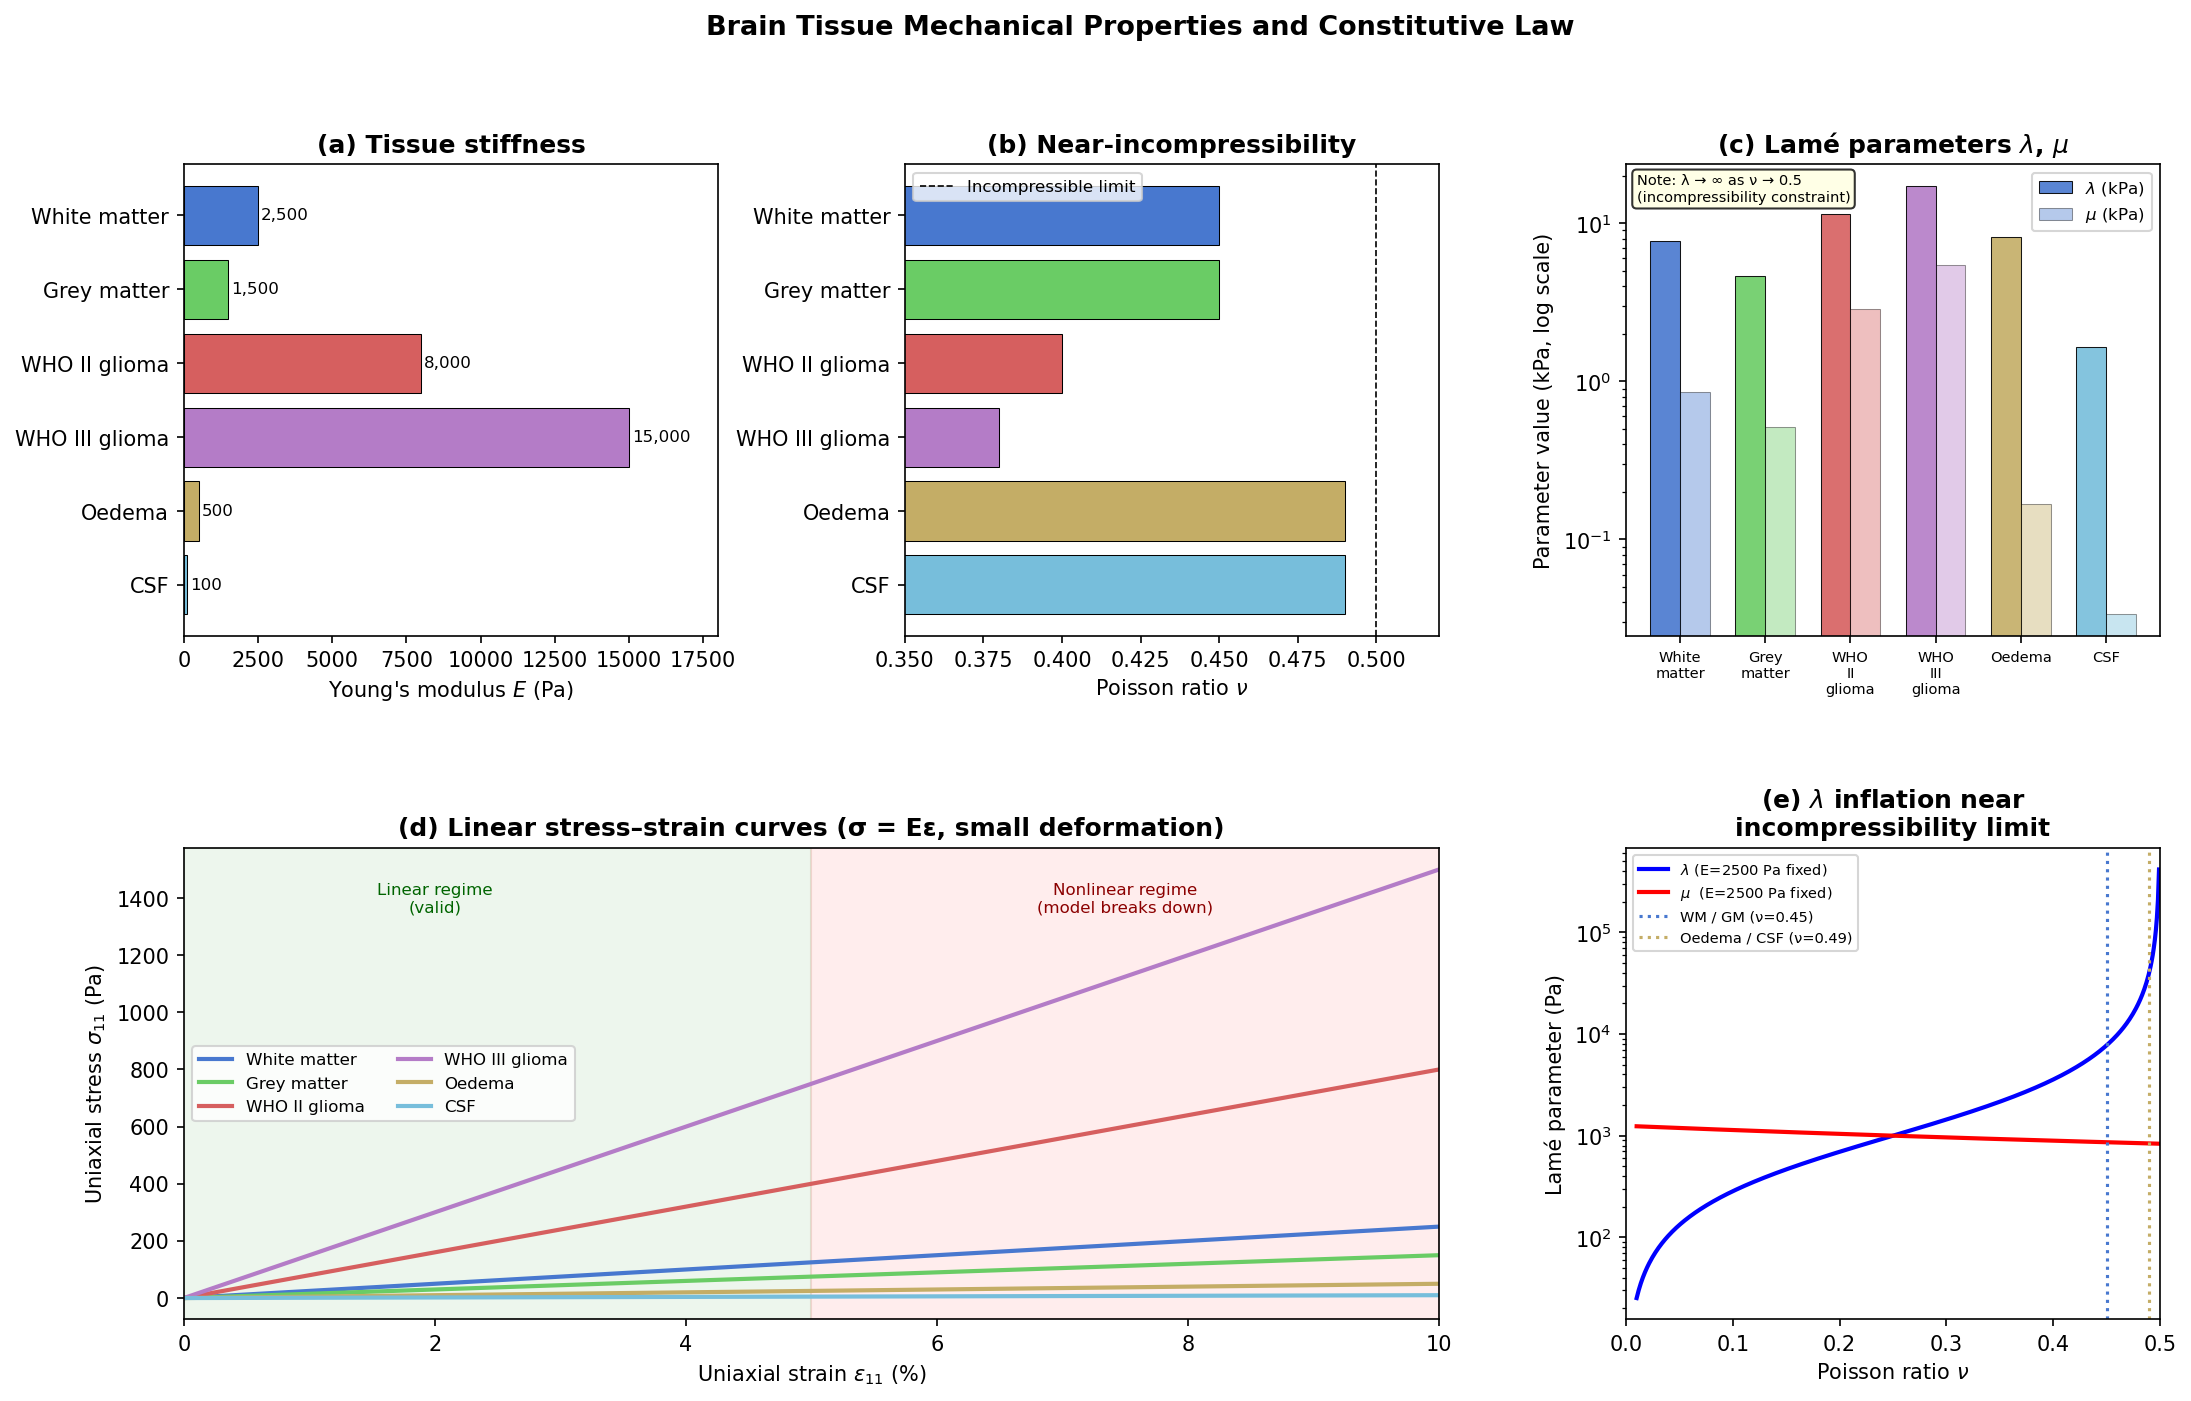

Lamé parameters for each tissue:
Tissue                  E (Pa)       ν        λ (Pa)    μ (Pa)
--------------------------------------------------------------
White matter             2,500   0.450         7,759       862
Grey matter              1,500   0.450         4,655       517
WHO II glioma            8,000   0.400        11,429     2,857
WHO III glioma          15,000   0.380        17,210     5,435
Oedema                     500   0.490         8,221       168
CSF                        100   0.490         1,644        34


In [52]:
# ── Cell 1A-1: Tissue material properties and constitutive law ───────────────
#
# Shows: (a) Young's modulus E and Poisson ratio ν per tissue class,
#         (b) derived Lamé parameters λ and μ,
#         (c) linear stress–strain curves demonstrating relative stiffness,
#         (d) how near-incompressibility (ν→0.5) inflates λ while μ stays finite.

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec

# ── Tissue library (SI units: Pa) ────────────────────────────────────────────
TISSUES = {
    'White matter':   dict(E=2500,  nu=0.45, color='#4878CF'),
    'Grey matter':    dict(E=1500,  nu=0.45, color='#6ACC65'),
    'WHO II glioma':  dict(E=8000,  nu=0.40, color='#D65F5F'),
    'WHO III glioma': dict(E=15000, nu=0.38, color='#B47CC7'),
    'Oedema':         dict(E=500,   nu=0.49, color='#C4AD66'),
    'CSF':            dict(E=100,   nu=0.49, color='#77BEDB'),
}

def lame(E, nu):
    lam = E * nu / ((1 + nu) * (1 - 2*nu))
    mu  = E / (2*(1 + nu))
    return lam, mu

names  = list(TISSUES.keys())
colors = [v['color'] for v in TISSUES.values()]
E_vals = np.array([v['E']  for v in TISSUES.values()])
nu_vals = np.array([v['nu'] for v in TISSUES.values()])
lam_vals, mu_vals = zip(*[lame(v['E'], v['nu']) for v in TISSUES.values()])
lam_vals = np.array(lam_vals)
mu_vals  = np.array(mu_vals)

fig = plt.figure(figsize=(17, 10))
fig.suptitle('Brain Tissue Mechanical Properties and Constitutive Law', fontsize=13, fontweight='bold')
gs = GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

# ── (a) Young's modulus bar chart ─────────────────────────────────────────────
ax0 = fig.add_subplot(gs[0, 0])
bars = ax0.barh(names, E_vals, color=colors, edgecolor='k', linewidth=0.5)
ax0.set_xlabel('Young\'s modulus $E$ (Pa)')
ax0.set_title('(a) Tissue stiffness', fontweight='bold')
for bar, val in zip(bars, E_vals):
    ax0.text(val + 100, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=8)
ax0.set_xlim(0, 18000)
ax0.invert_yaxis()

# ── (b) Poisson ratio ──────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 1])
ax1.barh(names, nu_vals, color=colors, edgecolor='k', linewidth=0.5)
ax1.axvline(0.5, color='k', linestyle='--', linewidth=0.8, label='Incompressible limit')
ax1.set_xlabel('Poisson ratio $\\nu$')
ax1.set_title('(b) Near-incompressibility', fontweight='bold')
ax1.set_xlim(0.35, 0.52)
ax1.legend(fontsize=8)
ax1.invert_yaxis()

# ── (c) Lamé parameters λ and μ ──────────────────────────────────────────────
ax2 = fig.add_subplot(gs[0, 2])
x = np.arange(len(names))
w = 0.35
ax2.bar(x - w/2, lam_vals/1e3, w, color=colors, alpha=0.9, edgecolor='k', linewidth=0.5, label='$\\lambda$ (kPa)')
ax2.bar(x + w/2, mu_vals/1e3,  w, color=colors, alpha=0.4, edgecolor='k', linewidth=0.5, label='$\\mu$ (kPa)')
ax2.set_yscale('log')
ax2.set_xticks(x)
ax2.set_xticklabels([n.replace(' ', '\n') for n in names], fontsize=7)
ax2.set_ylabel('Parameter value (kPa, log scale)')
ax2.set_title('(c) Lamé parameters $\\lambda$, $\\mu$', fontweight='bold')
ax2.legend(fontsize=8)
note = 'Note: λ → ∞ as ν → 0.5\n(incompressibility constraint)'
ax2.text(0.02, 0.98, note, transform=ax2.transAxes, fontsize=7,
         va='top', bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8))

# ── (d) Linear stress–strain curves ──────────────────────────────────────────
ax3 = fig.add_subplot(gs[1, 0:2])
eps_range = np.linspace(0, 0.10, 200)   # 0–10% uniaxial strain
for name, props, color in zip(names, TISSUES.values(), colors):
    E = props['E']
    nu = props['nu']
    # Uniaxial stress (plane stress approximation): σ = E·ε
    sigma = E * eps_range
    ax3.plot(eps_range * 100, sigma, color=color, lw=2, label=name)

ax3.set_xlabel('Uniaxial strain $\\varepsilon_{11}$ (%)')
ax3.set_ylabel('Uniaxial stress $\\sigma_{11}$ (Pa)')
ax3.set_title('(d) Linear stress–strain curves (σ = Eε, small deformation)', fontweight='bold')
ax3.legend(fontsize=8, ncol=2)
ax3.axvspan(0, 5, alpha=0.07, color='green', label='Small-deformation regime')
ax3.axvspan(5, 10, alpha=0.07, color='red')
ax3.text(2.0, 1350, 'Linear regime\n(valid)', fontsize=8, color='darkgreen', ha='center')
ax3.text(7.5, 1350, 'Nonlinear regime\n(model breaks down)', fontsize=8, color='darkred', ha='center')
ax3.set_xlim(0, 10)

# ── (e) λ inflation as ν → 0.5 ───────────────────────────────────────────────
ax4 = fig.add_subplot(gs[1, 2])
nu_sweep = np.linspace(0.01, 0.499, 500)
E_fixed  = 2500   # white matter E
lam_sweep = E_fixed * nu_sweep / ((1 + nu_sweep) * (1 - 2*nu_sweep))
mu_sweep  = E_fixed / (2*(1 + nu_sweep))
ax4.semilogy(nu_sweep, lam_sweep, 'b-', lw=2, label='$\\lambda$ (E=2500 Pa fixed)')
ax4.semilogy(nu_sweep, mu_sweep,  'r-', lw=2, label='$\\mu$  (E=2500 Pa fixed)')
ax4.axvline(0.45, color='#4878CF', linestyle=':', linewidth=1.5, label='WM / GM (ν=0.45)')
ax4.axvline(0.49, color='#C4AD66', linestyle=':', linewidth=1.5, label='Oedema / CSF (ν=0.49)')
ax4.set_xlabel('Poisson ratio $\\nu$')
ax4.set_ylabel('Lamé parameter (Pa)')
ax4.set_title('(e) $\\lambda$ inflation near\nincompressibility limit', fontweight='bold')
ax4.legend(fontsize=7)
ax4.set_xlim(0, 0.5)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC06_A1_material_properties.png', bbox_inches='tight')
plt.show()

print('Lamé parameters for each tissue:')
print(f"{'Tissue':20s}  {'E (Pa)':>8s}  {'ν':>6s}  {'λ (Pa)':>12s}  {'μ (Pa)':>8s}")
print('-' * 62)
for name, props in TISSUES.items():
    lam, mu = lame(props['E'], props['nu'])
    print(f"{name:20s}  {props['E']:>8,.0f}  {props['nu']:>6.3f}  {lam:>12,.0f}  {mu:>8,.0f}")

### Interpreting Figure A1: Brain Tissue Mechanical Properties and Constitutive Law

This figure introduces the material constants used in the mechanical model and shows how they translate into elastic behaviour.  The central idea is that each tissue class is assigned a stiffness $E$ and a Poisson ratio $\nu$, and from these two quantities we derive the Lam\'e parameters $\lambda$ and $\mu$ that appear in the linear elasticity equations.

**(a) Tissue stiffness.**  This panel compares Young\'s modulus across tissue classes.  White matter and grey matter are relatively soft, oedema is softer still, and CSF is the most compliant material in the set.  The glioma classes are assigned much higher stiffness values, especially the WHO III glioma, reflecting the modelling assumption that tumour tissue can resist deformation more strongly than surrounding parenchyma.  The practical implication is that stiffer regions will deform less for the same applied load.

**(b) Near-incompressibility.**  This panel shows the Poisson ratio $\nu$ for each tissue.  Values close to 0.5 indicate that the material changes shape more easily than volume, which is typical for water-rich tissues.  Oedema and CSF lie closest to the incompressible limit, while the glioma classes are somewhat less incompressible.  In biomechanical terms, this means fluid-rich tissues can still move substantially, but they strongly resist volume loss.

**(c) Lam\'e parameters $\lambda$ and $\mu$.**  These are the parameters actually used in the constitutive law.  The shear modulus $\mu$ mainly controls resistance to shape change, while $\lambda$ controls resistance to volumetric compression.  The log scale makes it clear that tissues with similar $E$ can still have very different $\lambda$ values when $\nu$ differs.  In particular, near-incompressible materials produce large $\lambda$, which is why oedema and CSF remain mechanically important despite their low Young\'s modulus.

**(d) Linear stress-strain curves.**  These lines show the constitutive rule $\sigma = E\,\varepsilon$ under uniaxial loading.  The slope of each line is exactly the Young\'s modulus, so steeper lines correspond to stiffer materials.  This makes the ranking from panel (a) visually intuitive: WHO III glioma stiffens fastest, CSF slowest, and white/grey matter lie in between.  The shaded right-hand region reminds the reader that linear elasticity is only a small-strain approximation and may become inaccurate once strains are no longer modest.

**(e) $\lambda$ inflation near the incompressibility limit.**  This panel highlights an important numerical and physical fact: as $\nu \to 0.5$, the Lam\'e parameter $\lambda$ increases dramatically, whereas $\mu$ remains comparatively well behaved.  This is why nearly incompressible materials are challenging in finite-element solvers and why the model avoids setting $\nu = 0.5$ exactly.  The plot gives intuition for how a seemingly small change in Poisson ratio can strongly change the volumetric penalty in the equations.

Taken together, the figure shows that brain mechanics is governed not only by "how stiff" a tissue is, but also by **how compressible** it is.  In this notebook, those two aspects are later made spatially varying with MRI-derived information, but this figure establishes the baseline constitutive behaviour for each tissue class.

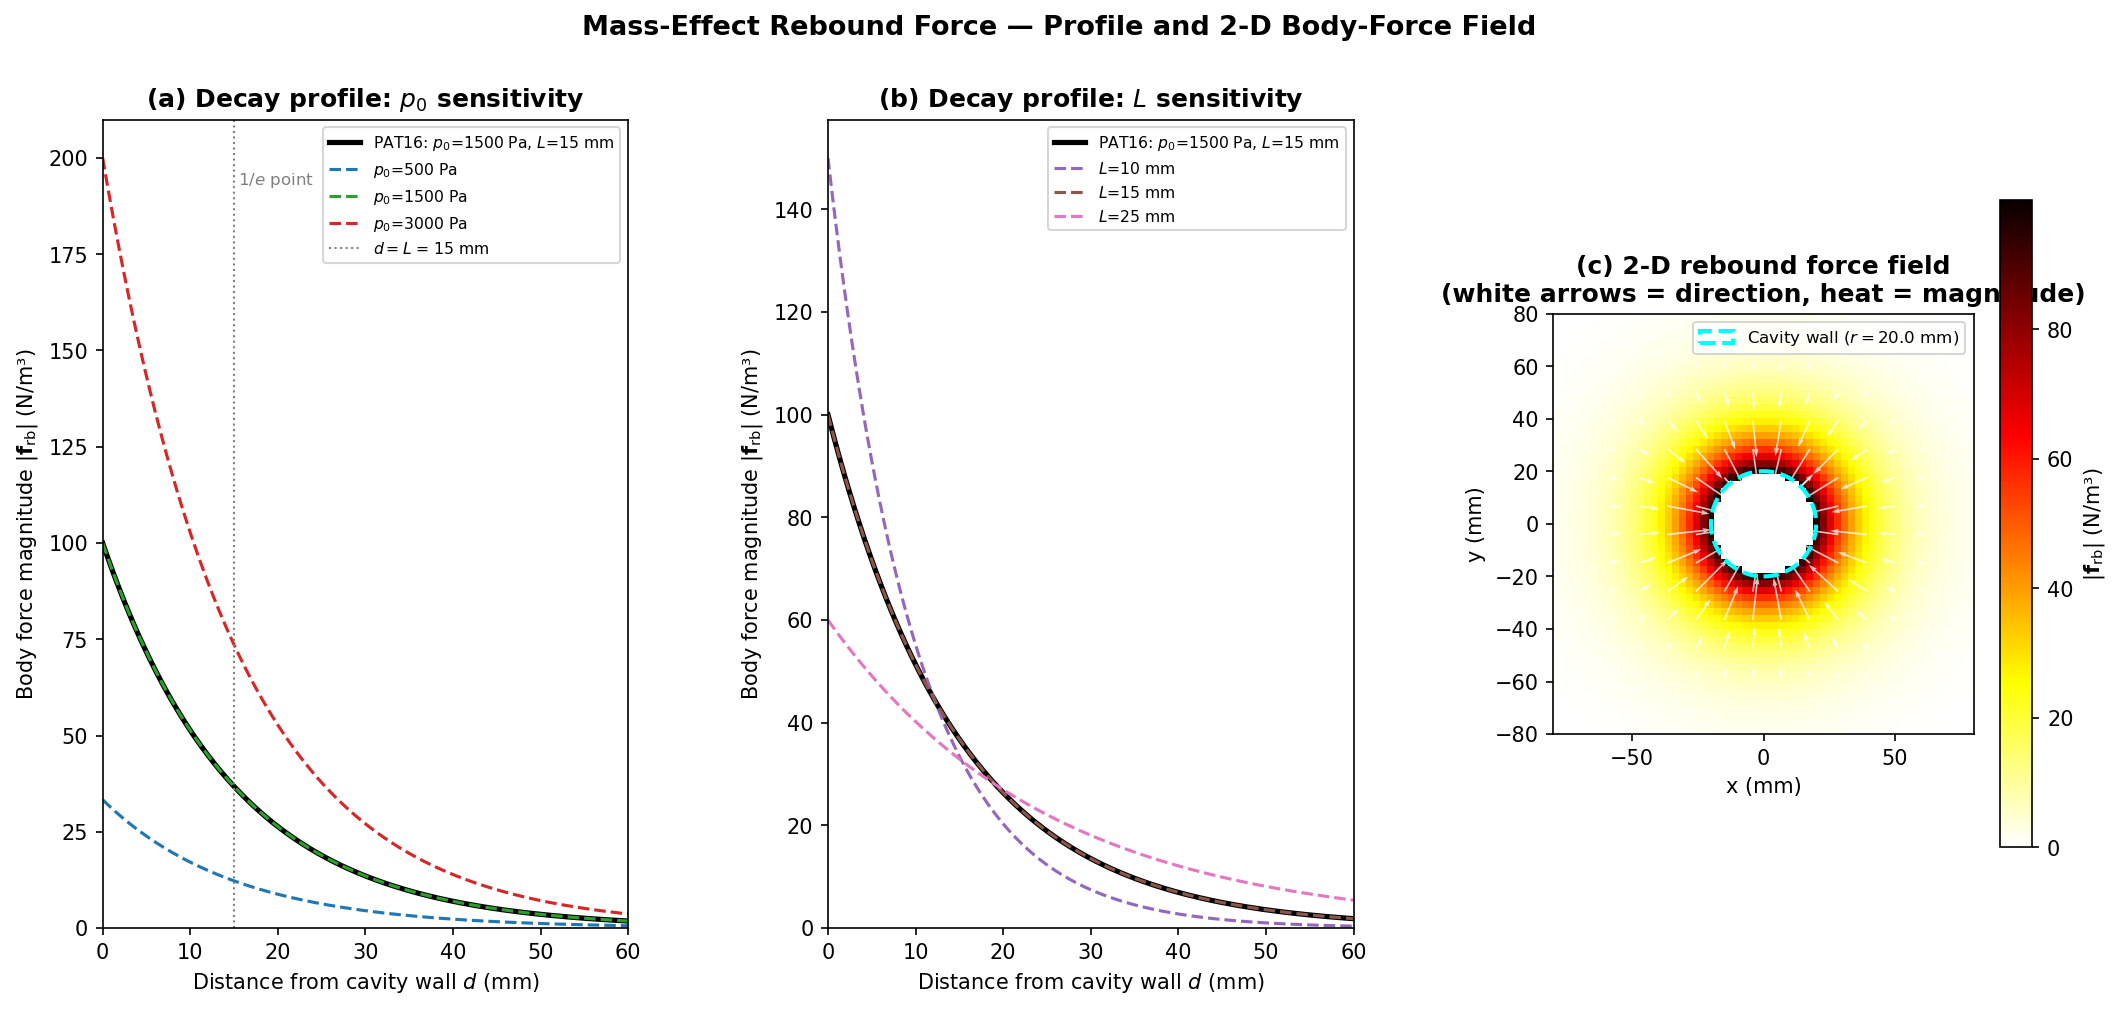

PAT16 (reference)             f(d=0mm)=100.0  f(d=5mm)=71.7  f(d=L=15mm)=36.8  N/m³
Low IFP (10 mmHg)             f(d=0mm)=33.3  f(d=5mm)=23.9  f(d=L=15mm)=12.3  N/m³
High IFP (25 mmHg)            f(d=0mm)=200.0  f(d=5mm)=143.3  f(d=L=15mm)=73.6  N/m³


In [53]:
# ── Cell 1A-2: Mass-effect rebound force — profile and 2-D field ─────────────
#
# Shows: (a) f_rebound(d) = (p0/L) exp(-d/L) versus distance from cavity boundary
#         for different p0 and L values (parameter sensitivity),
#        (b) 2-D quiver / colour map of the body force field around a circular
#         cavity, illustrating direction and magnitude.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Circle
from matplotlib.colors import Normalize
import matplotlib.cm as cm

fig = plt.figure(figsize=(17, 7))
fig.suptitle('Mass-Effect Rebound Force — Profile and 2-D Body-Force Field', fontsize=13, fontweight='bold')
gs = GridSpec(1, 3, figure=fig, wspace=0.38)

# ─── (a) 1-D decay profile: parameter sensitivity ────────────────────────────
ax0 = fig.add_subplot(gs[0, 0])
d_mm = np.linspace(0, 60, 400)          # distance from cavity wall (mm)

p0_vals = [500, 1500, 3000]             # Pa  (10, 22, 45 mmHg)
L_vals  = [10,  15,   25]               # mm  spatial decay

# Reference (PAT16 parameters)
p0_ref, L_ref = 1500, 15
f_ref = (p0_ref / L_ref) * np.exp(-d_mm / L_ref)
ax0.plot(d_mm, f_ref, 'k-', lw=2.5, label=f'PAT16: $p_0$={p0_ref} Pa, $L$={L_ref} mm')

palette_p0 = ['#1f77b4', '#2ca02c', '#d62728']
for p0, col in zip(p0_vals, palette_p0):
    f = (p0 / L_ref) * np.exp(-d_mm / L_ref)
    ax0.plot(d_mm, f, '--', color=col, lw=1.5, label=f'$p_0$={p0} Pa')

ax0.axvline(L_ref, color='gray', linestyle=':', lw=1, label=f'$d = L$ = {L_ref} mm')
ax0.set_xlabel('Distance from cavity wall $d$ (mm)')
ax0.set_ylabel('Body force magnitude $|\\mathbf{f}_\\mathrm{rb}|$ (N/m³)')
ax0.set_title('(a) Decay profile: $p_0$ sensitivity', fontweight='bold')
ax0.legend(fontsize=7.5)
ax0.set_xlim(0, 60); ax0.set_ylim(bottom=0)
ax0.text(L_ref+0.5, 0.92*ax0.get_ylim()[1],
         '$1/e$ point', fontsize=8, color='gray')

# ─── (b) 1-D decay profile: L sensitivity ────────────────────────────────────
ax1 = fig.add_subplot(gs[0, 1])
palette_L = ['#9467bd', '#8c564b', '#e377c2']
ax1.plot(d_mm, f_ref, 'k-', lw=2.5, label=f'PAT16: $p_0$={p0_ref} Pa, $L$={L_ref} mm')
for L, col in zip(L_vals, palette_L):
    f = (p0_ref / L) * np.exp(-d_mm / L)
    ax1.plot(d_mm, f, '--', color=col, lw=1.5, label=f'$L$={L} mm')

ax1.set_xlabel('Distance from cavity wall $d$ (mm)')
ax1.set_ylabel('Body force magnitude $|\\mathbf{f}_\\mathrm{rb}|$ (N/m³)')
ax1.set_title('(b) Decay profile: $L$ sensitivity', fontweight='bold')
ax1.legend(fontsize=7.5)
ax1.set_xlim(0, 60); ax1.set_ylim(bottom=0)

# ─── (c) 2-D force field around circular cavity ───────────────────────────────
ax2 = fig.add_subplot(gs[0, 2], aspect='equal')

R_cav  = 20.0          # mm – approximate radius of resection cavity
extent = 80.0          # mm – half-size of visualisation domain
N      = 60            # grid resolution for quiver

x1d = np.linspace(-extent, extent, N)
X, Y = np.meshgrid(x1d, x1d)
R    = np.sqrt(X**2 + Y**2)          # distance from cavity centre

# Distance from cavity wall (zero inside cavity)
d_field = np.maximum(R - R_cav, 0.0)

# Force magnitude (zero inside cavity)
Fmag = np.where(R > R_cav, (p0_ref / L_ref) * np.exp(-d_field / L_ref), 0.0)

# Direction: unit vector pointing inward (toward cavity centre)
with np.errstate(divide='ignore', invalid='ignore'):
    Fx = np.where(R > R_cav, -X / R * Fmag, 0.0)
    Fy = np.where(R > R_cav, -Y / R * Fmag, 0.0)

# Plot colour map of magnitude
im = ax2.imshow(Fmag, origin='lower', extent=[-extent, extent, -extent, extent],
                cmap='hot_r', vmin=0, vmax=Fmag.max())
plt.colorbar(im, ax=ax2, label='$|\\mathbf{f}_\\mathrm{rb}|$ (N/m³)', shrink=0.8)

# Quiver (subsample for readability)
step = 4
ax2.quiver(X[::step, ::step], Y[::step, ::step],
           Fx[::step, ::step], Fy[::step, ::step],
           color='white', scale=None, scale_units='xy',
           width=0.004, alpha=0.75)

# Draw cavity boundary
cavity_circ = Circle((0, 0), R_cav, fill=False, edgecolor='cyan', linewidth=2,
                     linestyle='--', label=f'Cavity wall ($r={R_cav}$ mm)')
ax2.add_patch(cavity_circ)
ax2.set_xlabel('x (mm)'); ax2.set_ylabel('y (mm)')
ax2.set_title('(c) 2-D rebound force field\n(white arrows = direction, heat = magnitude)',
              fontweight='bold')
ax2.legend(fontsize=8, loc='upper right')
ax2.set_xlim(-extent, extent); ax2.set_ylim(-extent, extent)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC06_A2_rebound_force.png', bbox_inches='tight')
plt.show()

# ─── Numerical summary ────────────────────────────────────────────────────────
for desc, p0, L in [('PAT16 (reference)', 1500, 15),
                    ('Low IFP (10 mmHg)', 500, 15),
                    ('High IFP (25 mmHg)', 3000, 15)]:
    f0 = p0 / L          # force at cavity wall (N/m³)
    f5 = f0 * np.exp(-5  / L)
    f15 = f0 * np.exp(-15 / L)
    print(f'{desc:28s}  f(d=0mm)={f0:.1f}  f(d=5mm)={f5:.1f}  f(d=L={L}mm)={f15:.1f}  N/m³')

### Interpreting Figure A2: Mass-Effect Rebound Force

This figure explains the simplified body-force model used to represent the mechanical rebound that occurs after tumour removal.  The idea is that tissue surrounding the cavity has stored elastic energy and an elevated local pressure before surgery; once the tumour is removed, that constraint is released and the surrounding parenchyma is pulled or driven inward toward the cavity.  In the model, this effect is represented by an exponentially decaying body force,

$$
\mathbf{f}_{\mathrm{rebound}}(\mathbf{x}) = \frac{p_0}{L}\,e^{-d(\mathbf{x})/L}\,\hat{\mathbf{r}}_{\mathrm{in}}(\mathbf{x}),
$$

where $p_0$ sets the force scale, $L$ sets the decay length, $d(\mathbf{x})$ is the distance from the cavity wall, and $\hat{\mathbf{r}}_{\mathrm{in}}$ points inward.

**(a) Decay profile: $p_0$ sensitivity.**  This panel shows how the rebound-force magnitude changes with distance from the cavity wall when the decay length $L$ is fixed and the pressure scale $p_0$ is varied.  Increasing $p_0$ raises the entire curve, meaning the force is stronger everywhere, but the shape of the decay stays the same.  The vertical line at $d=L$ marks the characteristic length scale where the force has dropped to about $1/e$ of its boundary value.  The interpretation is straightforward: higher tumour-associated pressure before resection leads to a stronger post-resection mechanical rebound.

**(b) Decay profile: $L$ sensitivity.**  Here the pressure scale is held fixed and the decay length $L$ is varied.  Smaller $L$ gives a more localised force concentrated near the cavity wall, while larger $L$ spreads the force over a wider surrounding region.  In physical terms, $L$ controls how deeply the mass-effect release penetrates into the tissue.  This matters because two models with the same boundary strength can produce different displacement fields depending on whether the rebound is highly local or broadly distributed.

**(c) 2-D rebound force field.**  This panel turns the 1-D decay law into a spatial field around an idealised circular cavity.  The colour map shows force magnitude, which is highest at the cavity boundary and decreases outward, while the arrows show direction, pointing radially inward toward the cavity.  The picture gives intuition for how the force acts in the simulation: it is not a surface traction alone, but a distributed volumetric load in the surrounding tissue.  The strongest mechanical effect is therefore expected near the cavity margin, with influence tapering off with distance.

Taken together, the three panels show that the rebound-force model has two clinically meaningful control parameters: **$p_0$**, which sets how strong the released pressure is, and **$L$**, which sets how far that effect extends into the brain.  The reference PAT16 choice sits between weaker and stronger alternatives, providing a plausible first-order description of post-resection mass-effect release rather than a direct measurement of tissue pressure.

FA:    shape=(160, 256, 256), range=[0.000, 1.060]
MD:    shape=(160, 256, 256), range=[-0.0001, 0.0082] mm²/s
Tumor: unique values = [0.0, 5.580546257988317e-06, 1.5336934666265734e-05, 2.653359842952341e-05, 2.662514816620387e-05, 2.809422767313663e-05, 3.043558172066696e-05, 3.4405173209961504e-05, 4.28927487519104e-05, 5.435803905129433e-05, 6.297602521954104e-05, 7.437498425133526e-05, 7.87884127930738e-05, 8.388062269659713e-05, 9.348616731585935e-05, 0.00011158687993884087, 0.00011444831034168601, 0.00011692560656229034, 0.00011943189019802958, 0.0001307244092458859, 0.0001354289415758103, 0.00014729055692441761, 0.0001485781540395692, 0.00015155925939325243, 0.00015445408644154668, 0.00016572646563872695, 0.0001730978983687237, 0.00018156899022869766, 0.0001825022918637842, 0.0001903345255414024, 0.00019186644931323826, 0.00021711098088417202, 0.00022240604448597878, 0.00022879471362102777, 0.00023530281032435596, 0.00024291363661177456, 0.00024663214571774006, 0.00027648764080

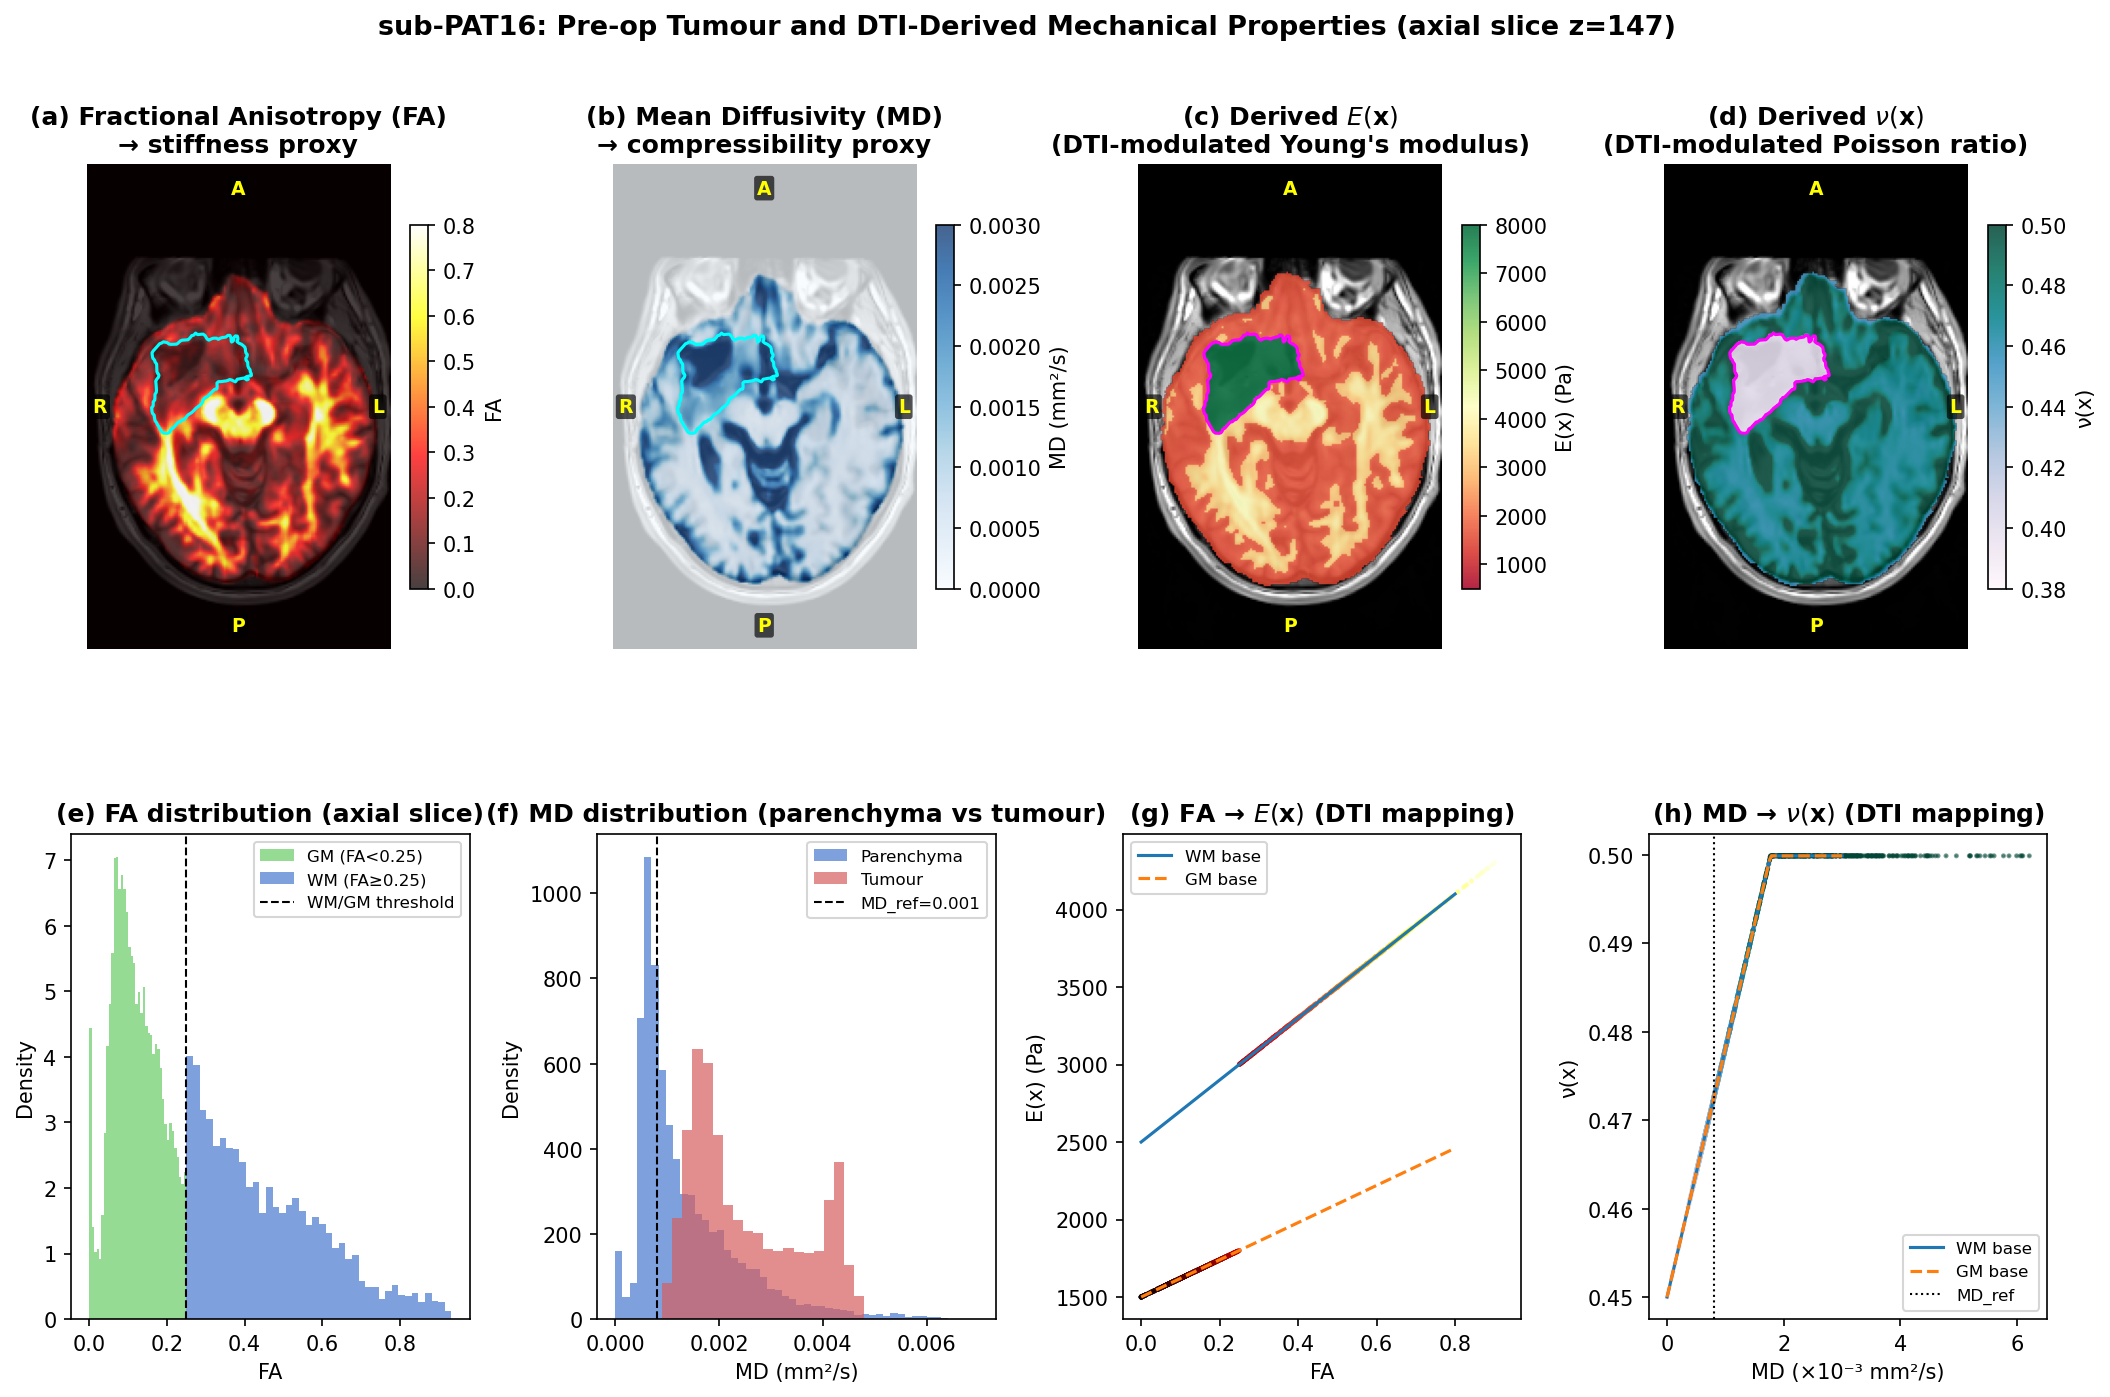

In [54]:
# ── Cell 1A-3: PAT16 – DTI-derived stiffness maps ────────────────────────────
#
# Loads FA, MD, and the tumour mask (all registered to post-op T1w space)
# and computes the spatially varying Young's modulus E(x) and Poisson ratio ν(x)
# used as FEM material properties.
#
# FA  → E(x) = E_base × (1 + α_FA × FA(x))     [α_FA = 0.8]
# MD  → ν(x) = ν_base × (1 + β_MD × MD/MD_ref)  [β_MD = 0.05, MD_ref = 0.8e-3 mm²/s]
# Tumour voxels use glioma-class constants (override DTI).

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# ─── Paths ────────────────────────────────────────────────────────────────────
fa_path    = LONG_DIR / 'fa_preop_in_postop.nii.gz'
md_path    = LONG_DIR / 'md_preop_in_postop.nii.gz'
tumor_path = LONG_DIR / 'tumor_preop_in_postop.nii.gz'
t1_path    = LONG_DIR / 'T1w_preop_in_postop.nii.gz'

def load_vol(path):
    return np.asarray(nib.load(str(path)).dataobj).astype(np.float32)

fa_vol    = load_vol(fa_path)
md_vol    = load_vol(md_path)
tumor_vol = load_vol(tumor_path)
t1_vol    = load_vol(t1_path)

print(f'FA:    shape={fa_vol.shape}, range=[{fa_vol.min():.3f}, {fa_vol.max():.3f}]')
print(f'MD:    shape={md_vol.shape}, range=[{md_vol.min():.4f}, {md_vol.max():.4f}] mm²/s')
print(f'Tumor: unique values = {np.unique(tumor_vol).tolist()}')
print('Reference orientation:', nib.orientations.aff2axcodes(nib.load(str(t1_path)).affine))

# ─── DTI → E(x) and ν(x) ─────────────────────────────────────────────────────
# Base tissue classes: simple WM/GM split by FA threshold
ALPHA_FA = 0.8
BETA_MD  = 0.05
MD_REF   = 0.8e-3      # typical parenchyma MD (mm²/s)

E_WM, nu_WM = 2500.0, 0.45
E_GM, nu_GM = 1500.0, 0.45
E_TU, nu_TU = 8000.0, 0.40   # WHO II glioma defaults

brain_mask = (fa_vol > 0) | (tumor_vol > 0)

# Classify each voxel as WM (FA > 0.25) or GM otherwise
E_base  = np.where(fa_vol > 0.25, E_WM,  E_GM)
nu_base = np.where(fa_vol > 0.25, nu_WM, nu_GM)

# DTI-modulated fields
E_map  = E_base  * (1.0 + ALPHA_FA * np.clip(fa_vol, 0, 1))
nu_map = np.clip(nu_base * (1.0 + BETA_MD * md_vol / MD_REF), 0, 0.4999)

# Override tumour voxels
E_map[ tumor_vol > 0.5]  = E_TU
nu_map[tumor_vol > 0.5]  = nu_TU

# Mask to brain only
E_map[~brain_mask]  = 0
nu_map[~brain_mask] = 0

print(f'E(x):  range in brain = [{E_map[brain_mask].min():.0f}, {E_map[brain_mask].max():.0f}] Pa')
print(f'ν(x):  range in brain = [{nu_map[brain_mask].min():.4f}, {nu_map[brain_mask].max():.4f}]')

# ─── Choose axial slice through tumour region ─────────────────────────────────
# Find slice with largest tumour cross-section (axis=2 = axial)
tumor_counts = (tumor_vol > 0.5).sum(axis=(0, 1))
z_best = int(np.argmax(tumor_counts))
print(f'Displaying axial slice z={z_best} (largest tumour cross-section)')

# Volumes are in canonical RAS+, so flip axis 0 for radiological display
# (patient right appears on the viewer's left) while keeping anterior at the top.
def slc(vol, z=z_best):
    return vol[::-1, :, z].T

# ─── Plot ──────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(17, 10))
fig.suptitle(f'sub-PAT16: Pre-op Tumour and DTI-Derived Mechanical Properties (axial slice z={z_best})',
             fontsize=13, fontweight='bold')
gs = GridSpec(2, 4, figure=fig, hspace=0.38, wspace=0.32)

# T1w anatomy (background reference)
def show_t1(ax, z=z_best):
    t1_sl = slc(t1_vol, z)
    p1, p99 = np.percentile(t1_sl[t1_sl > 0], [1, 99]) if (t1_sl > 0).any() else (0, 1)
    ax.imshow(t1_sl, cmap='gray', origin='lower', vmin=p1, vmax=p99)

CMAP_FA  = 'hot'
CMAP_MD  = 'Blues'
CMAP_E   = 'RdYlGn'
CMAP_NU  = 'PuBuGn'

def add_orientation_labels(ax):
    kw = dict(transform=ax.transAxes, fontsize=9, fontweight='bold', color='yellow',
              zorder=10, bbox=dict(boxstyle='round,pad=0.15', fc='#000000aa', lw=0))
    ax.text(0.02, 0.50, 'R', va='center', ha='left',   **kw)
    ax.text(0.98, 0.50, 'L', va='center', ha='right',  **kw)
    ax.text(0.50, 0.97, 'A', va='top',    ha='center', **kw)
    ax.text(0.50, 0.03, 'P', va='bottom', ha='center', **kw)

def overlay_tumor(ax, z=z_best, color='cyan', alpha=0.4):
    tu = slc(tumor_vol, z)
    ax.contour(tu, levels=[0.5], colors=[color], linewidths=[1.5])

# ── Row 0: DTI maps ────────────────────────────────────────────────────────────
# (0,0) FA
ax = fig.add_subplot(gs[0, 0])
show_t1(ax)
im = ax.imshow(slc(fa_vol), cmap=CMAP_FA, origin='lower', alpha=0.75, vmin=0, vmax=0.8)
overlay_tumor(ax)
add_orientation_labels(ax)
plt.colorbar(im, ax=ax, shrink=0.75, label='FA')
ax.set_title('(a) Fractional Anisotropy (FA)\n→ stiffness proxy', fontweight='bold')
ax.axis('off')

# (0,1) MD
ax = fig.add_subplot(gs[0, 1])
show_t1(ax)
md_display = np.clip(slc(md_vol), 0, 3e-3)
im = ax.imshow(md_display, cmap=CMAP_MD, origin='lower', alpha=0.75, vmin=0, vmax=3e-3)
overlay_tumor(ax)
add_orientation_labels(ax)
plt.colorbar(im, ax=ax, shrink=0.75, label='MD (mm²/s)')
ax.set_title('(b) Mean Diffusivity (MD)\n→ compressibility proxy', fontweight='bold')
ax.axis('off')

# (0,2) E(x) map
ax = fig.add_subplot(gs[0, 2])
show_t1(ax)
E_sl = slc(E_map)
E_sl_masked = np.ma.masked_where(E_sl == 0, E_sl)
im = ax.imshow(E_sl_masked, cmap=CMAP_E, origin='lower', alpha=0.85, vmin=500, vmax=8000)
overlay_tumor(ax, color='magenta')
add_orientation_labels(ax)
plt.colorbar(im, ax=ax, shrink=0.75, label='E(x) (Pa)')
ax.set_title('(c) Derived $E(\\mathbf{x})$\n(DTI-modulated Young\'s modulus)', fontweight='bold')
ax.axis('off')

# (0,3) ν(x) map
ax = fig.add_subplot(gs[0, 3])
show_t1(ax)
nu_sl = slc(nu_map)
nu_sl_masked = np.ma.masked_where(nu_sl == 0, nu_sl)
im = ax.imshow(nu_sl_masked, cmap=CMAP_NU, origin='lower', alpha=0.85, vmin=0.38, vmax=0.5)
overlay_tumor(ax, color='magenta')
add_orientation_labels(ax)
plt.colorbar(im, ax=ax, shrink=0.75, label='ν(x)')
ax.set_title('(d) Derived $\\nu(\\mathbf{x})$\n(DTI-modulated Poisson ratio)', fontweight='bold')
ax.axis('off')

# ── Row 1: Histograms and scatter ─────────────────────────────────────────────
brain_pix = brain_mask[:, :, z_best]

# (1,0) FA histogram: WM vs GM (by threshold)
ax = fig.add_subplot(gs[1, 0])
fa_brain = fa_vol[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5)]
ax.hist(fa_brain[fa_brain < 0.25], bins=40, color='#6ACC65', alpha=0.7,
        label='GM (FA<0.25)', density=True)
ax.hist(fa_brain[fa_brain >= 0.25], bins=40, color='#4878CF', alpha=0.7,
        label='WM (FA≥0.25)', density=True)
ax.axvline(0.25, color='k', linestyle='--', lw=1, label='WM/GM threshold')
ax.set_xlabel('FA'); ax.set_ylabel('Density')
ax.set_title('(e) FA distribution (axial slice)', fontweight='bold')
ax.legend(fontsize=8)

# (1,1) MD histogram: parenchyma vs tumour
ax = fig.add_subplot(gs[1, 1])
md_par   = md_vol[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5) &
                                  (md_vol[:, :, z_best] > 0)]
md_tumor = md_vol[:, :, z_best][tumor_vol[:, :, z_best] > 0.5]
ax.hist(md_par,   bins=50, color='#4878CF', alpha=0.7, label='Parenchyma', density=True)
ax.hist(md_tumor, bins=20, color='#D65F5F', alpha=0.7, label='Tumour', density=True)
ax.axvline(MD_REF, color='k', linestyle='--', lw=1, label=f'MD_ref={MD_REF:.3f}')
ax.set_xlabel('MD (mm²/s)'); ax.set_ylabel('Density')
ax.set_title('(f) MD distribution (parenchyma vs tumour)', fontweight='bold')
ax.legend(fontsize=8)

# (1,2) FA → E scatter
ax = fig.add_subplot(gs[1, 2])
fa_flat = fa_vol[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5)].ravel()
E_flat  = E_map[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5)].ravel()
fa_flat = fa_flat[E_flat > 0]; E_flat = E_flat[E_flat > 0]
ax.scatter(fa_flat[::10], E_flat[::10], c=fa_flat[::10], cmap='hot',
           s=2, alpha=0.5, rasterized=True)
fa_line = np.linspace(0, 0.8, 100)
for E_b, label, ls in [(E_WM, 'WM base', '-'), (E_GM, 'GM base', '--')]:
    ax.plot(fa_line, E_b * (1 + ALPHA_FA * fa_line), ls, lw=1.5, label=label)
ax.set_xlabel('FA'); ax.set_ylabel('E(x) (Pa)')
ax.set_title('(g) FA → $E(\\mathbf{x})$ (DTI mapping)', fontweight='bold')
ax.legend(fontsize=8)

# (1,3) MD → ν scatter
ax = fig.add_subplot(gs[1, 3])
md_flat  = md_vol[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5)].ravel()
nu_flat  = nu_map[:, :, z_best][brain_pix & (tumor_vol[:, :, z_best] < 0.5)].ravel()
md_flat = md_flat[nu_flat > 0]; nu_flat = nu_flat[nu_flat > 0]
ax.scatter(md_flat[::10]*1e3, nu_flat[::10], c=nu_flat[::10], cmap='PuBuGn',
           s=2, alpha=0.5, rasterized=True)
md_line = np.linspace(0, 3e-3, 100)
for nu_b, label, ls in [(nu_WM, 'WM base', '-'), (nu_GM, 'GM base', '--')]:
    ax.plot(md_line*1e3, np.clip(nu_b*(1 + BETA_MD*md_line/MD_REF), 0, 0.4999),
            ls, lw=1.5, label=label)
ax.axvline(MD_REF*1e3, color='k', linestyle=':', lw=1, label='MD_ref')
ax.set_xlabel('MD (×10⁻³ mm²/s)'); ax.set_ylabel('ν(x)')
ax.set_title('(h) MD → $\\nu(\\mathbf{x})$ (DTI mapping)', fontweight='bold')
ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC06_A3_dti_stiffness.png', bbox_inches='tight')
plt.show()

### Interpreting Figure A3: DTI-Derived Mechanical Properties

This figure links diffusion MRI measurements to the material-property fields used in the finite-element model.  The top row shows **where** the imaging-derived quantities are located in the brain, while the bottom row shows **how** those quantities are distributed and mapped into mechanical parameters.  The orientation labels follow **radiological display**: patient **R** appears on the viewer's left, **L** on the right, **A** at the top, and **P** at the bottom.  The axial slice is chosen from the **largest pre-op tumour cross-section**, and the overlaid contour in panels (a) and (b) is the **pre-op tumour mask** in post-op anatomical space.  This is different from the displacement/Jacobian figure later in the notebook, which uses a **post-op cavity-based slice** and a **cavity contour**.

**(a) Fractional anisotropy (FA) → stiffness proxy.**  FA is high in coherent white-matter bundles and low in more isotropic grey matter or oedematous tissue.  In this slice, the brightest FA values are concentrated in organised white matter, whereas the pre-op tumour region outlined in cyan disrupts the normal anisotropic pattern.  Because the model uses FA to increase Young's modulus, bright regions in panel (a) correspond to tissue that is assumed to be mechanically stiffer.

**(b) Mean diffusivity (MD) → compressibility proxy.**  MD measures the overall magnitude of water diffusion.  Higher MD often reflects increased free water content, reduced tissue density, oedema, necrosis, or partial-volume mixing with CSF.  The elevated MD near and within the lesion therefore suggests more fluid-like tissue, which in the model is translated into a higher Poisson ratio, that is, more nearly incompressible behaviour.

**(c) Derived $E(\mathbf{x})$.**  This panel shows the spatially varying Young's modulus obtained from the FA-based mapping.  White-matter regions with elevated FA become stiffer, whereas tissue with lower FA remains closer to the grey-matter baseline.  The tumour mask is shown in magenta; within this region the model assigns a fixed glioma-class modulus rather than relying on the FA value alone.  The resulting map captures spatial heterogeneity in tissue stiffness across the slice.

**(d) Derived $\nu(\mathbf{x})$.**  This panel shows the Poisson-ratio field derived from MD.  Regions with higher MD shift upward toward the near-incompressible limit, whereas more typical parenchyma remains closer to the baseline value.  Inside the tumour, the Poisson ratio is again overridden by a tumour-specific constant.  Together, panels (c) and (d) define the voxelwise elastic material properties used by the FEM.

**(e) FA distribution in the axial slice.**  The histogram separates low-FA voxels (interpreted here as grey matter-like) from high-FA voxels (white matter-like) using the threshold FA = 0.25.  The broad rightward tail indicates a substantial white-matter contribution, while the left peak reflects more isotropic tissue.  This threshold is a simple but practical way to partition tissue classes for the mechanical model.

**(f) MD distribution: parenchyma versus tumour.**  This histogram compares diffusivity in the surrounding brain and within the tumour.  The tumour distribution is shifted toward higher MD, consistent with altered microstructure and increased water mobility in lesional tissue.  The vertical reference line marks the characteristic parenchymal value $\mathrm{MD}_{\mathrm{ref}}$, which anchors the mapping from MD to Poisson ratio.

**(g) FA to $E(\mathbf{x})$ mapping.**  This scatter plot visualises the rule used to convert FA into Young's modulus.  The two straight trend lines correspond to the grey-matter and white-matter baselines, so voxels on the white-matter branch remain stiffer across the FA range.  The figure makes clear that the mapping is monotonic: increasing FA leads to increasing stiffness.

**(h) MD to $\nu(\mathbf{x})$ mapping.**  This panel shows the mapping from MD to Poisson ratio.  As MD increases, $\nu$ rises until it reaches the cap near 0.5, which prevents the material from becoming numerically incompressible in the linear elastic solver.  The flattening at the top therefore reflects the imposed upper bound rather than a biological saturation law.

Taken together, the figure shows how diffusion MRI is used to move from qualitative tissue contrast to **patient-specific mechanical parameters**.  The main modelling assumption is that **high FA implies stiffer tissue** and **high MD implies more incompressible, fluid-rich tissue**.  This is a biologically plausible first-order approximation, but it remains a surrogate model rather than a direct measurement of elasticity.

Reference orientation: ('R', 'A', 'S')
Axial slices at z=122 (max cavity cross-section)
Canonical axis codes: ('R', 'A', 'S')  (expected R, A, S)
  FEM baseline (gravity)      : max=0.31 mm  mean=0.02 mm  median=0.00 mm
  FEM improved (+mass eff)    : max=2.08 mm  mean=0.10 mm  median=0.00 mm
  Empirical (ANTs SyN)        : max=6.14 mm  mean=0.61 mm  median=0.37 mm
  Jacobian range (brain): [0.365, 2.735]


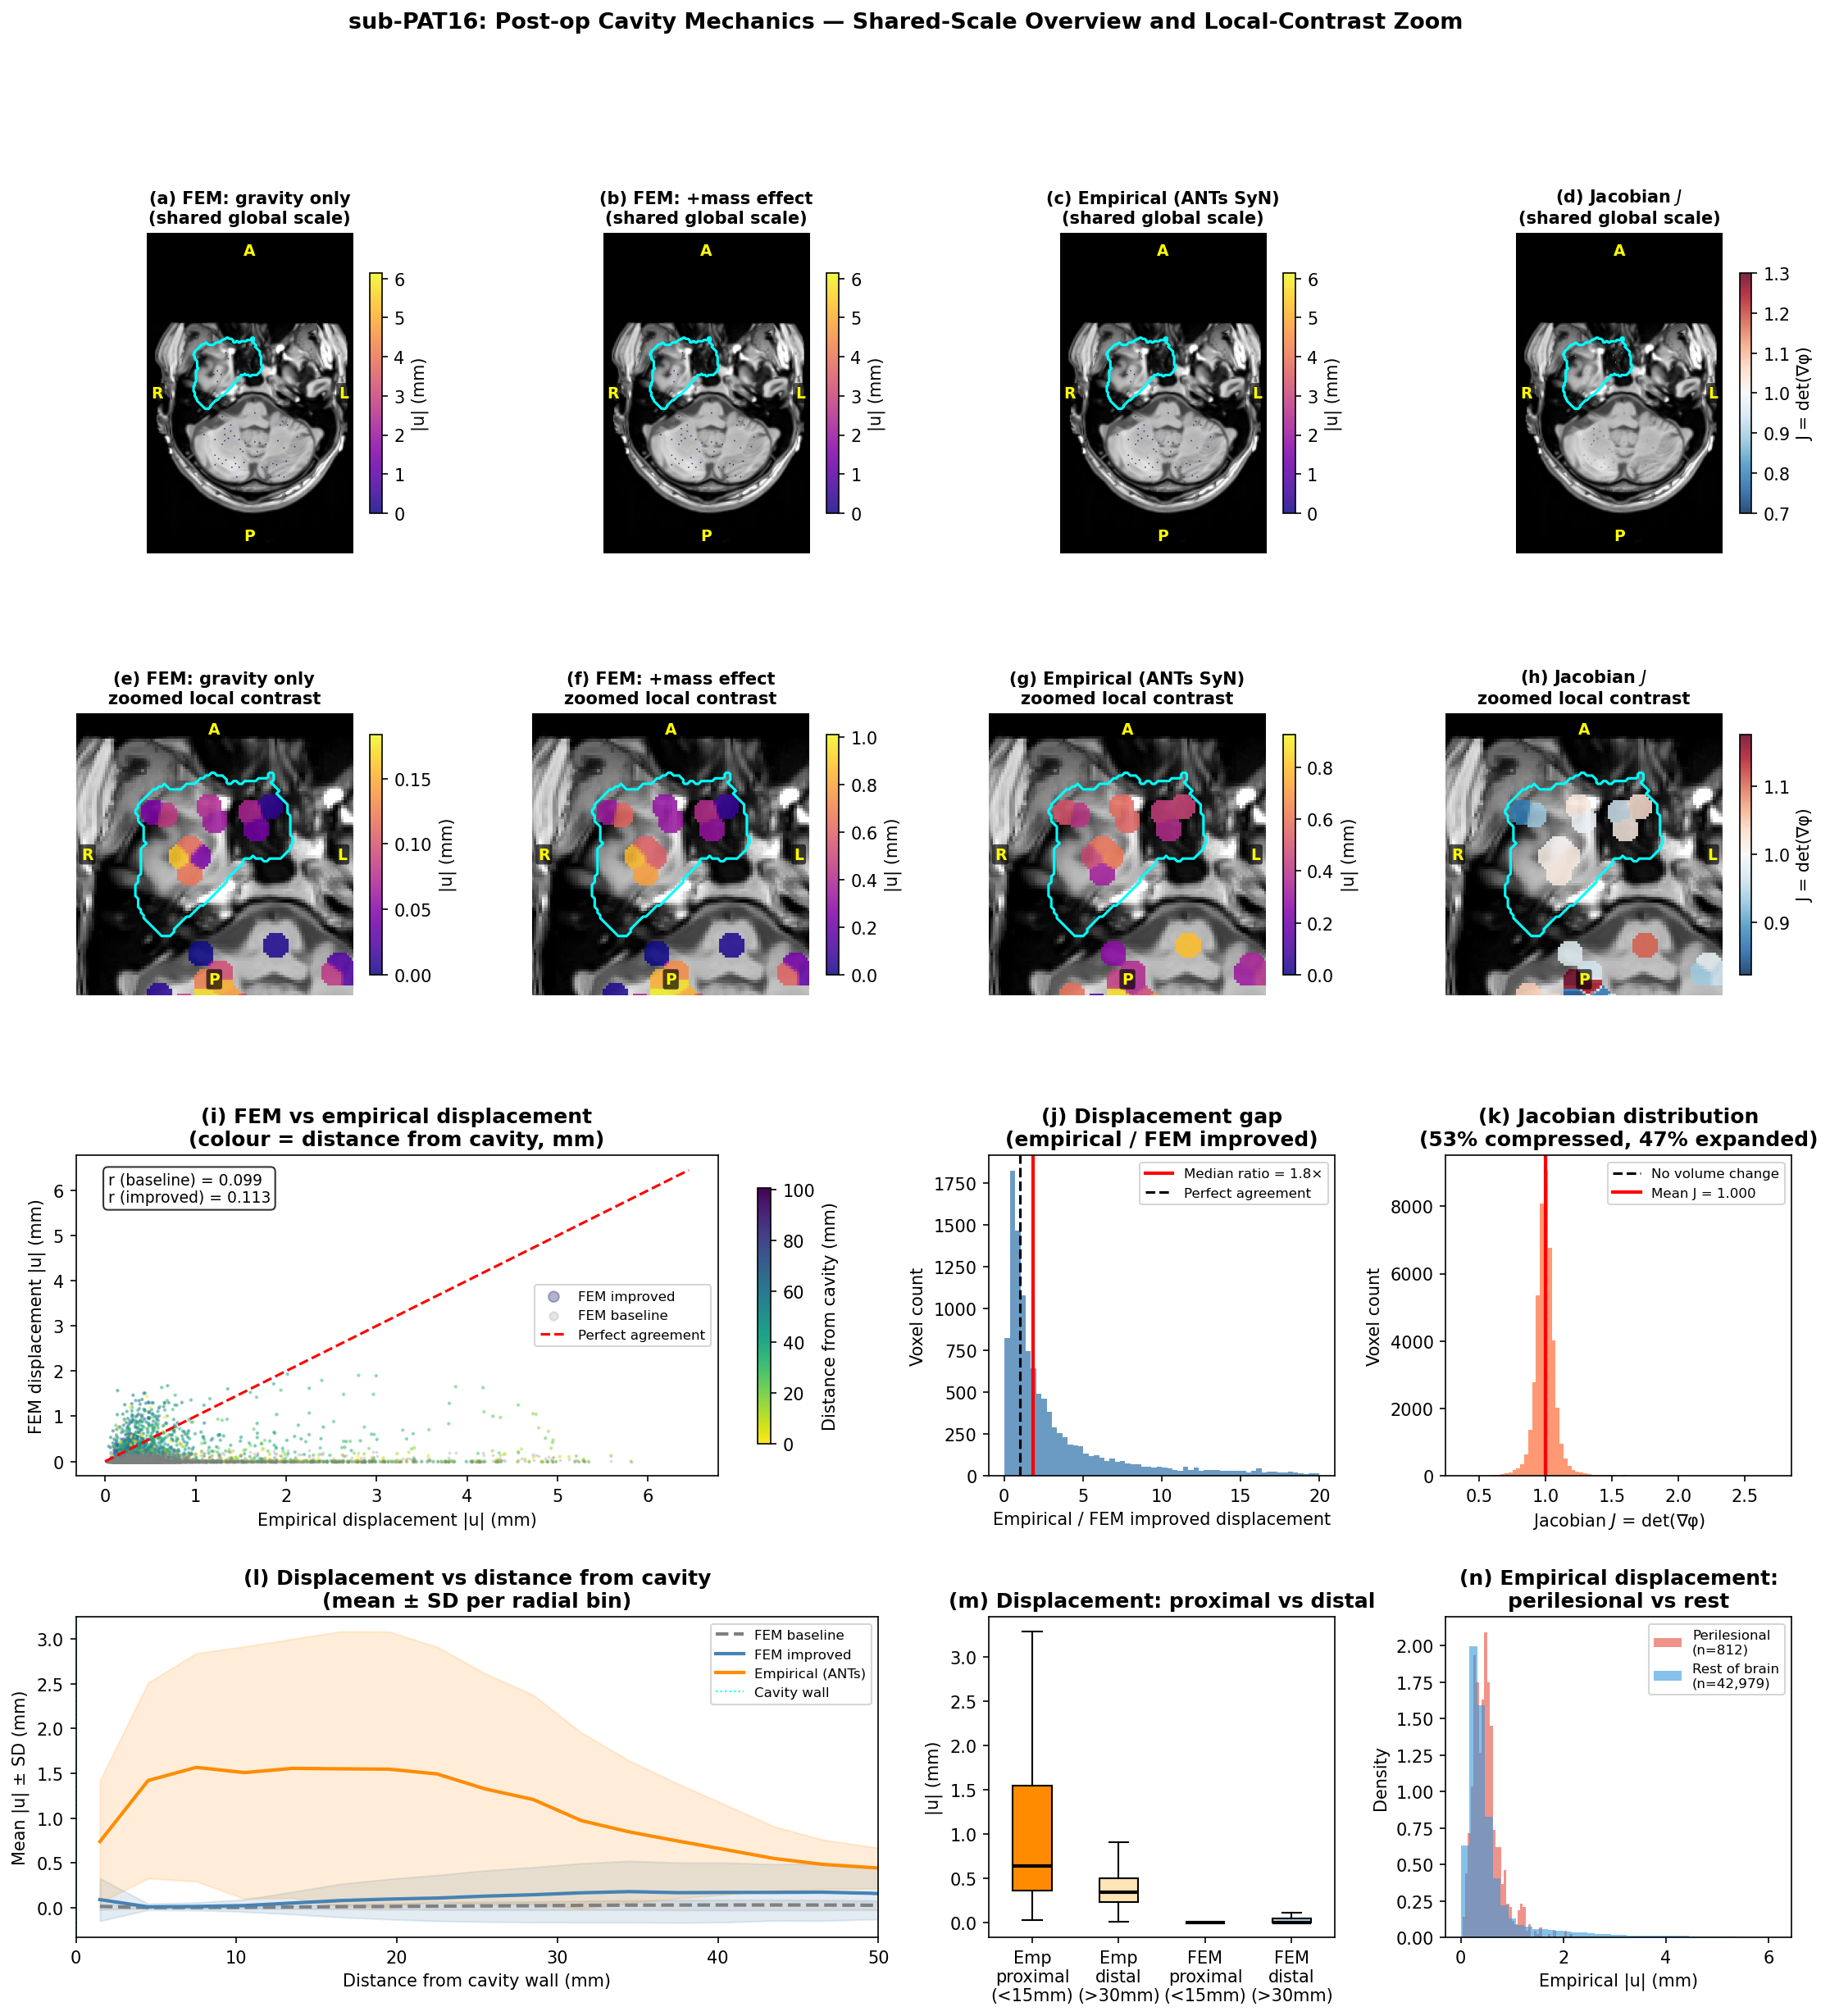


── Summary (brain voxels) ──────────────────────────────────────────────
Field                              Max    Mean   Median  (mm)
------------------------------------------------------------
FEM baseline (gravity)            0.31    0.02     0.00
FEM improved (+mass eff)          2.08    0.10     0.00
Empirical (ANTs SyN)              6.14    0.61     0.37

Jacobian:  min=0.365  max=2.735  mean=1.000
  → 53.1% of brain voxels compressed (J<1),  46.9% expanded (J>1)


In [55]:
# ── Cell 1A-4: PAT16 – Displacement fields, Jacobian, and cavity analysis ─────
#
# Loads all three displacement fields and the Jacobian determinant det(∇φ):
#   · FEM baseline  (gravity only)
#   · FEM improved  (gravity + mass-effect rebound)
#   · Empirical     (ANTs SyN pre→post T1w registration)
#   · Jacobian      (J<1 = compression, J>1 = expansion)
#   · Perilesional  (zone within ~20 mm of cavity)
#   · Cavity mask
#
# Panels: (a–d) full-slice maps with shared global scales for comparability
#         (e–h) cavity-centred zooms with slice-specific local contrast
#         (i–n) quantitative validation and distance-based summaries

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.ndimage import distance_transform_edt, gaussian_filter

# ─── Load volumes (all resampled to canonical RAS+ reference space) ───────────
from nibabel.processing import resample_from_to

# Reorient reference to canonical RAS+ so axis 0=R, 1=A, 2=S is guaranteed
_ref_img = nib.as_closest_canonical(
    nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz'))
)
print('Reference orientation:', nib.orientations.aff2axcodes(_ref_img.affine))

def load_vol(path, ref=_ref_img, order=1):
    """Load a NIfTI, reorient to canonical RAS+, resample into ref space."""
    img = nib.as_closest_canonical(nib.load(str(path)))
    if img.shape[:3] != ref.shape[:3] or not np.allclose(img.affine, ref.affine, atol=1e-4):
        img = resample_from_to(img, ref, order=order)
    return np.asarray(img.dataobj).astype(np.float32)

fem_impr_vol = np.asarray(_ref_img.dataobj).astype(np.float32)           # reference (RAS+)
fem_base_vol = load_vol(LONG_DIR / 'fem_displacement_magnitude.nii.gz')
emp_disp_vol = load_vol(LONG_DIR / 'displacement_magnitude.nii.gz')
jac_vol      = load_vol(LONG_DIR / 'jacobian_preop_to_postop.nii.gz')
cavity_vol   = load_vol(LONG_DIR / 'cavity_mask_postop.nii.gz',   order=0)  # nearest for masks
peril_vol    = load_vol(LONG_DIR / 'perilesional.nii.gz',         order=0)
t1_vol2      = load_vol(LONG_DIR / 'T1w_preop_in_postop.nii.gz')

# Verify all shapes match
assert fem_base_vol.shape == fem_impr_vol.shape == emp_disp_vol.shape, \
    "Shape mismatch after resampling — check file paths"

brain_mask = fem_impr_vol > 0

# ─── Affine voxel size (for mm) ──────────────────────────────────────────────
aff   = nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz')).affine
vox_mm = float(np.abs(aff[0, 0]))   # isotropic assumed

# ─── Best axial slice (largest cavity cross-section) ─────────────────────────
n_cav = (cavity_vol > 0.5).sum(axis=(0, 1))
z_cav = int(np.argmax(n_cav))
print(f'Axial slices at z={z_cav} (max cavity cross-section)')

# Verify canonical orientation codes – must be ('R', 'A', 'S')
axcodes = nib.orientations.aff2axcodes(_ref_img.affine)
print(f'Canonical axis codes: {axcodes}  (expected R, A, S)')
# axis 0 = axcodes[0], axis 1 = axcodes[1], axis 2 (slice) = axcodes[2]
# For axial display: we slice along axis 2 (S), display axis 0 (R) and axis 1 (A).
# Radiological convention: patient Right on viewer's Left  → flip axis 0.
# Standard axial orientation: Anterior at top, Posterior at bottom → keep axis 1 with origin='lower'.
def slc(vol, z=z_cav):
    """RAS+ canonical: flip R-axis → radiological (patient R on viewer's left)."""
    return vol[::-1, :, z].T

def add_orientation_labels(ax):
    """Stamp R / L / A / P on the four sides of an axial panel."""
    kw = dict(transform=ax.transAxes, fontsize=9, fontweight='bold', color='yellow',
              zorder=10, bbox=dict(boxstyle='round,pad=0.15', fc='#000000aa', lw=0))
    ax.text(0.02, 0.50, 'R', va='center', ha='left',   **kw)   # viewer's left  = patient R
    ax.text(0.98, 0.50, 'L', va='center', ha='right',  **kw)   # viewer's right = patient L
    ax.text(0.50, 0.97, 'A', va='top',    ha='center', **kw)   # top            = Anterior
    ax.text(0.50, 0.03, 'P', va='bottom', ha='center', **kw)   # bottom         = Posterior

# ─── Summary stats ────────────────────────────────────────────────────────────
for name, vol in [('FEM baseline (gravity)', fem_base_vol),
                  ('FEM improved (+mass eff)', fem_impr_vol),
                  ('Empirical (ANTs SyN)', emp_disp_vol)]:
    v = vol[brain_mask]
    print(f'  {name:28s}: max={v.max():.2f} mm  mean={v.mean():.2f} mm  median={np.median(v):.2f} mm')

print(f'  Jacobian range (brain): [{jac_vol[brain_mask].min():.3f}, {jac_vol[brain_mask].max():.3f}]')

# ─── Distance from cavity wall (mm) ──────────────────────────────────────────
# distance_transform_edt gives voxels from nearest non-zero; we want distance
# *from* the cavity *outward* — so EDToftheinverse
cavity_binary = (cavity_vol > 0.5).astype(np.uint8)
dist_from_cav = distance_transform_edt(1 - cavity_binary) * vox_mm   # mm

# ─── Slice-specific helpers ───────────────────────────────────────────────────
slice_brain  = slc(brain_mask.astype(np.float32)) > 0.5
slice_cavity = slc(cavity_vol) > 0.5

def masked_slice(vol):
    sl = slc(vol)
    return np.ma.masked_where(~slice_brain, sl)

def smooth_for_display(masked, sigma=1.0):
    """Display-only smoothing that respects the brain mask."""
    data = np.ma.filled(masked, 0.0)
    weights = (~np.ma.getmaskarray(masked)).astype(np.float32)
    data_s = gaussian_filter(data, sigma=sigma)
    weights_s = gaussian_filter(weights, sigma=sigma)
    smoothed = np.divide(data_s, weights_s, out=np.zeros_like(data_s), where=weights_s > 1e-6)
    return np.ma.masked_where(weights_s <= 1e-6, smoothed)

def slice_disp_limits(vol):
    vals = slc(vol)[slice_brain]
    vmax = float(np.percentile(vals, 99)) if vals.size else 1.0
    return 0.0, max(vmax, 0.05)

def slice_jac_limits(vol):
    vals = slc(vol)[slice_brain]
    p1, p99 = np.percentile(vals, [1, 99])
    delta = max(1.0 - float(p1), float(p99) - 1.0, 0.03)
    return 1.0 - delta, 1.0 + delta

ys, xs = np.where(slice_cavity)
if xs.size:
    pad = 22
    x0 = max(int(xs.min()) - pad, 0)
    x1 = min(int(xs.max()) + pad, slice_cavity.shape[1] - 1)
    y0 = max(int(ys.min()) - pad, 0)
    y1 = min(int(ys.max()) + pad, slice_cavity.shape[0] - 1)
else:
    x0, x1 = 0, slice_cavity.shape[1] - 1
    y0, y1 = 0, slice_cavity.shape[0] - 1

def apply_zoom(ax):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)

# ─── Figure layout ────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 18))
fig.suptitle('sub-PAT16: Post-op Cavity Mechanics — Shared-Scale Overview and Local-Contrast Zoom',
             fontsize=13, fontweight='bold')
gs = GridSpec(4, 4, figure=fig, hspace=0.44, wspace=0.32)

def show_anat(ax, z=z_cav):
    t1_sl = slc(t1_vol2, z)
    p1, p99 = np.percentile(t1_sl[t1_sl > 0], [1, 99]) if (t1_sl > 0).any() else (0, 1)
    ax.imshow(t1_sl, cmap='gray', origin='lower', vmin=p1, vmax=p99)

def show_cavity(ax, z=z_cav):
    ax.contour(slc(cavity_vol, z), levels=[0.5], colors=['cyan'], linewidths=[1.5])

def draw_overlay(ax, data2d, cmap, vmin, vmax, cbar_label, title, zoom=False):
    show_anat(ax)
    im = ax.imshow(data2d, cmap=cmap, origin='lower', vmin=vmin, vmax=vmax, alpha=0.85)
    show_cavity(ax)
    add_orientation_labels(ax)
    if zoom:
        apply_zoom(ax)
    plt.colorbar(im, ax=ax, shrink=0.75, label=cbar_label)
    ax.set_title(title, fontweight='bold', fontsize=10, pad=6)
    ax.axis('off')

# ── Row 0: Full-slice maps with shared scales ────────────────────────────────
disp_max = float(emp_disp_vol[brain_mask].max())
disp_shared = [
    ('(a) FEM: gravity only\n(shared global scale)', fem_base_vol),
    ('(b) FEM: +mass effect\n(shared global scale)', fem_impr_vol),
    ('(c) Empirical (ANTs SyN)\n(shared global scale)', emp_disp_vol),
]
for col, (title, vol) in enumerate(disp_shared):
    ax = fig.add_subplot(gs[0, col])
    draw_overlay(ax, masked_slice(vol), 'plasma', 0, disp_max, '|u| (mm)', title, zoom=False)

ax = fig.add_subplot(gs[0, 3])
draw_overlay(
    ax,
    masked_slice(jac_vol),
    'RdBu_r',
    0.7,
    1.3,
    'J = det(∇φ)',
    '(d) Jacobian $J$\n(shared global scale)',
    zoom=False,
)

# ── Row 1: Cavity-centred zooms with local contrast ──────────────────────────
for col, (title, vol) in enumerate([
        ('(e) FEM: gravity only\nzoomed local contrast', fem_base_vol),
        ('(f) FEM: +mass effect\nzoomed local contrast', fem_impr_vol),
        ('(g) Empirical (ANTs SyN)\nzoomed local contrast', emp_disp_vol)]):
    ax = fig.add_subplot(gs[1, col])
    vmin, vmax = slice_disp_limits(vol)
    draw_overlay(ax, smooth_for_display(masked_slice(vol)), 'plasma', vmin, vmax,
                 '|u| (mm)', title, zoom=True)

ax = fig.add_subplot(gs[1, 3])
j_vmin, j_vmax = slice_jac_limits(jac_vol)
draw_overlay(
    ax,
    smooth_for_display(masked_slice(jac_vol)),
    'RdBu_r',
    j_vmin,
    j_vmax,
    'J = det(∇φ)',
    '(h) Jacobian $J$\nzoomed local contrast',
    zoom=True,
)

# ── Rows 2–3: Quantitative summaries ─────────────────────────────────────────
mask_flat = brain_mask.ravel()
base_flat = fem_base_vol.ravel()[mask_flat]
impr_flat = fem_impr_vol.ravel()[mask_flat]
emp_flat  = emp_disp_vol.ravel()[mask_flat]
d_flat    = dist_from_cav.ravel()[mask_flat]
jac_flat  = jac_vol.ravel()[mask_flat]

# Scatter: improved FEM vs empirical (1:10 subsample)
ax = fig.add_subplot(gs[2, 0:2])
step = 10
ax.scatter(emp_flat[::step], impr_flat[::step],
           c=d_flat[::step], cmap='viridis_r', s=1.5, alpha=0.4,
           rasterized=True, label='FEM improved')
ax.scatter(emp_flat[::step], base_flat[::step],
           c='gray', s=1, alpha=0.2, rasterized=True, label='FEM baseline')
lim = max(emp_flat.max(), impr_flat.max()) * 1.05
ax.plot([0, lim], [0, lim], 'r--', lw=1.5, label='Perfect agreement')
r_base = np.corrcoef(emp_flat, base_flat)[0, 1]
r_impr = np.corrcoef(emp_flat, impr_flat)[0, 1]
ax.text(0.05, 0.95,
        f'r (baseline) = {r_base:.3f}\nr (improved) = {r_impr:.3f}',
        transform=ax.transAxes, va='top', fontsize=9,
        bbox=dict(boxstyle='round', fc='white', alpha=0.8))
ax.set_xlabel('Empirical displacement |u| (mm)')
ax.set_ylabel('FEM displacement |u| (mm)')
ax.set_title('(i) FEM vs empirical displacement\n(colour = distance from cavity, mm)',
             fontweight='bold')
ax.legend(fontsize=8, markerscale=5)
sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=plt.Normalize(0, d_flat.max()))
plt.colorbar(sm, ax=ax, label='Distance from cavity (mm)', shrink=0.8)

# Displacement gap histogram
ax = fig.add_subplot(gs[2, 2])
ratio = np.where(impr_flat > 0.01, emp_flat / impr_flat, np.nan)
ratio_valid = ratio[np.isfinite(ratio) & (ratio < 20)]
ax.hist(ratio_valid, bins=60, color='steelblue', edgecolor='none', alpha=0.8)
ax.axvline(np.nanmedian(ratio), color='r', lw=2,
           label=f'Median ratio = {np.nanmedian(ratio):.1f}×')
ax.axvline(1.0, color='k', lw=1.5, linestyle='--', label='Perfect agreement')
ax.set_xlabel('Empirical / FEM improved displacement')
ax.set_ylabel('Voxel count')
ax.set_title('(j) Displacement gap\n(empirical / FEM improved)', fontweight='bold')
ax.legend(fontsize=8)

# Jacobian histogram
ax = fig.add_subplot(gs[2, 3])
ax.hist(jac_flat[jac_flat > 0], bins=80, color='coral', edgecolor='none', alpha=0.8)
ax.axvline(1.0, color='k', lw=1.5, linestyle='--', label='No volume change')
ax.axvline(jac_flat[jac_flat > 0].mean(), color='r', lw=2,
           label=f'Mean J = {jac_flat[jac_flat > 0].mean():.3f}')
compressed_pct = 100 * (jac_flat[jac_flat > 0] < 1).mean()
expanded_pct   = 100 * (jac_flat[jac_flat > 0] > 1).mean()
ax.set_xlabel('Jacobian $J$ = det(∇φ)')
ax.set_ylabel('Voxel count')
ax.set_title(f'(k) Jacobian distribution\n({compressed_pct:.0f}% compressed, '
             f'{expanded_pct:.0f}% expanded)', fontweight='bold')
ax.legend(fontsize=8)

# Mean displacement vs distance from cavity wall
ax = fig.add_subplot(gs[3, 0:2])
d_bins = np.arange(0, 55, 3)   # mm bins
d_centres = 0.5 * (d_bins[:-1] + d_bins[1:])

def profile(vol_flat):
    means, stds = [], []
    for d0, d1 in zip(d_bins[:-1], d_bins[1:]):
        in_bin = (d_flat >= d0) & (d_flat < d1)
        v = vol_flat[in_bin]
        means.append(v.mean() if len(v) > 5 else np.nan)
        stds.append(v.std() if len(v) > 5 else np.nan)
    return np.array(means), np.array(stds)

for name, vol_flat, col, ls in [
        ('FEM baseline',     base_flat, 'gray',       '--'),
        ('FEM improved',     impr_flat, 'steelblue',  '-'),
        ('Empirical (ANTs)', emp_flat,  'darkorange', '-')]:
    m, s = profile(vol_flat)
    ax.plot(d_centres, m, ls, color=col, lw=2, label=name)
    ax.fill_between(d_centres, m - s, m + s, alpha=0.15, color=col)

ax.axvline(0, color='cyan', lw=1, linestyle=':', label='Cavity wall')
ax.set_xlabel('Distance from cavity wall (mm)')
ax.set_ylabel('Mean |u| ± SD (mm)')
ax.set_title('(l) Displacement vs distance from cavity\n(mean ± SD per radial bin)',
             fontweight='bold')
ax.legend(fontsize=8)
ax.set_xlim(0, 50)

# Boxplots: proximal (<15 mm) vs distal (>30 mm)
ax = fig.add_subplot(gs[3, 2])
proximal = d_flat < 15
distal   = d_flat > 30
data_box = [emp_flat[proximal], emp_flat[distal], impr_flat[proximal], impr_flat[distal]]
tick_labels = ['Emp\nproximal\n(<15mm)', 'Emp\ndistal\n(>30mm)',
               'FEM\nproximal\n(<15mm)', 'FEM\ndistal\n(>30mm)']
bp = ax.boxplot(data_box, tick_labels=tick_labels, patch_artist=True, showfliers=False,
                medianprops=dict(color='black', lw=2))
palette = ['darkorange', 'moccasin', 'steelblue', 'lightblue']
for patch, col in zip(bp['boxes'], palette):
    patch.set_facecolor(col)
ax.set_ylabel('|u| (mm)')
ax.set_title('(m) Displacement: proximal vs distal', fontweight='bold')

# Perilesional vs rest of brain
ax = fig.add_subplot(gs[3, 3])
peril_mask = (peril_vol > 0) & brain_mask
nonperil   = brain_mask & ~peril_mask
for name, mask, col in [('Perilesional', peril_mask, '#E74C3C'),
                        ('Rest of brain', nonperil,  '#3498DB')]:
    vals = emp_disp_vol[mask]
    ax.hist(vals, bins=40, color=col, alpha=0.6,
            label=f'{name}\n(n={mask.sum():,})', density=True)
ax.set_xlabel('Empirical |u| (mm)')
ax.set_ylabel('Density')
ax.set_title('(n) Empirical displacement:\nperilesional vs rest', fontweight='bold')
ax.legend(fontsize=8)

plt.tight_layout()
fig.savefig(FIG_DIR / 'figC06_A4_displacement_analysis.png', bbox_inches='tight')
plt.show()

# ─── Numerical summary table ──────────────────────────────────────────────────
print('\n── Summary (brain voxels) ──────────────────────────────────────────────')
print(f"{'Field':30s}  {'Max':>6s}  {'Mean':>6s}  {'Median':>7s}  (mm)")
print('-' * 60)
for nm, vol in [('FEM baseline (gravity)',    fem_base_vol),
                ('FEM improved (+mass eff)',  fem_impr_vol),
                ('Empirical (ANTs SyN)',      emp_disp_vol)]:
    v = vol[brain_mask]
    print(f'{nm:30s}  {v.max():6.2f}  {v.mean():6.2f}  {np.median(v):7.2f}')
print(f'\nJacobian:  min={jac_vol[brain_mask].min():.3f}  '
      f'max={jac_vol[brain_mask].max():.3f}  '
      f'mean={jac_vol[brain_mask].mean():.3f}')
print(f'  → {compressed_pct:.1f}% of brain voxels compressed (J<1),  '
      f'{expanded_pct:.1f}% expanded (J>1)')

### Interpreting Figure A4: Post-op Cavity Mechanics, Displacement, and Jacobian

This figure compares model-predicted and MRI-derived post-operative deformation in PAT16.  Unlike the DTI-property figure above, the axial slice here is chosen from the **largest post-op cavity cross-section**, and the cyan contour marks the **post-op resection cavity**.  The first row uses **shared global colour scales** so the panels are directly comparable.  The second row shows the same slice with **cavity-centred zoom**, **slice-specific contrast**, and mild **display-only smoothing**, making subtle spatial trends visible without changing the underlying quantitative analysis.

**(a) FEM: gravity only, shared global scale.**  This panel shows the displacement predicted when gravity is the only driving force, displayed on the same colour scale used for the other displacement maps.  Because the absolute displacement is very small, the panel appears nearly uncoloured.  That visual subtlety is itself informative: gravity alone contributes very little to the observed post-operative shift.

**(b) FEM: + mass effect, shared global scale.**  Adding the rebound-force term increases displacement near the cavity, but on the shared scale the signal is still modest relative to the empirical field.  This panel is useful for direct comparison with (a) and (c), because the same colour range is preserved across all three maps.

**(c) Empirical (ANTs SyN), shared global scale.**  This is the data-driven displacement field estimated from pre-op to post-op image registration.  On the same scale used in (a) and (b), the empirical deformation clearly shows broader and stronger high-displacement regions.  This makes the model underestimation visually obvious.

**(d) Jacobian $J$, shared global scale.**  The Jacobian determinant summarises local volume change, with $J<1$ indicating compression and $J>1$ expansion.  On the broad global scale, much of the slice lies near the neutral colour around $J=1$, so the panel looks visually restrained.  This is expected when local deviations from unit volume change are present but not extreme.

**(e) FEM: gravity only, local contrast + zoom, display-smoothed.**  This panel revisits (a) using a cavity-centred zoom and a slice-specific colour range, with mild smoothing applied for display only.  The previously hidden displacement pattern now becomes visible as a weak but spatially coherent field around the cavity margin.  The meaningful interpretation is the broad cavity-adjacent trend, not isolated pixel-scale hotspots.

**(f) FEM: + mass effect, local contrast + zoom, display-smoothed.**  With local contrast and mild display smoothing, the improved FEM field is much easier to inspect.  The displacement concentrates around the cavity and forms a smoother cavity-oriented pattern that is qualitatively similar to the empirical map.  This supports the interpretation that mass-effect release is a necessary part of the mechanism.

**(g) Empirical (ANTs SyN), local contrast + zoom, display-smoothed.**  This zoomed empirical panel highlights where the strongest observed deformation sits relative to the cavity.  The smoothing helps reveal contiguous regions of elevated displacement rather than voxel-level texture.  The biologically meaningful result is the broad peri-cavity organisation of the observed shift.

**(h) Jacobian $J$, local contrast + zoom, display-smoothed.**  This panel uses a narrower, slice-specific Jacobian range so local compression and expansion become easier to see, and the display smoothing makes the pattern more anatomically readable.  The resulting mixed field around the cavity shows that post-resection deformation is spatially heterogeneous rather than a simple uniform inward collapse.

**(i) FEM vs empirical displacement.**  This scatter plot compares voxelwise FEM predictions with empirical displacement.  The dashed diagonal marks perfect agreement, while colour indicates distance from the cavity wall.  The clustering of points below the diagonal shows that the FEM generally underestimates the empirical shift, although the correlation improves slightly when mass effect is included.

**(j) Displacement gap (empirical / FEM improved).**  This histogram shows how much larger the empirical displacement is relative to the improved FEM prediction.  A ratio of 1 would mean perfect agreement; values above 1 indicate underestimation by the model.  The median above unity confirms that the improved FEM still predicts too little displacement in much of the brain.

**(k) Jacobian distribution.**  This histogram summarises the brain-wide distribution of $J$.  The dashed line at $J=1$ marks no local volume change, and the percentages in the title quantify how much of the tissue is compressed versus expanded.  The distribution being centred close to 1 implies that the deformation mainly reflects local volume redistribution rather than large net global change.

**(l) Displacement vs distance from cavity.**  This panel averages displacement as a function of distance from the cavity wall.  The empirical curve is highest near the cavity and decays outward, matching the intuition that the strongest shift occurs adjacent to the resection site.  The FEM curves show the same qualitative trend but with smaller amplitude, especially for the gravity-only case.

**(m) Displacement: proximal vs distal.**  These boxplots compare displacement in tissue close to the cavity with tissue farther away, for both the empirical field and the improved FEM.  In both cases the proximal region moves more than the distal region, which is mechanically sensible.  However, the empirical values remain larger, showing that the model captures the spatial ordering better than the absolute magnitude.

**(n) Empirical displacement: perilesional vs rest.**  This histogram compares empirical displacement in the perilesional zone with the rest of the brain.  The perilesional distribution is shifted toward larger values, indicating that the strongest observed deformation is concentrated near the lesion and cavity environment rather than being uniform throughout the brain.

Taken together, the figure now provides both **fair global comparison** and **readable local detail**.  The shared-scale row makes it clear that gravity alone is too weak and that the improved FEM still falls short of the empirical field.  The local-contrast row shows that the model does reproduce meaningful cavity-adjacent structure, even though important physics such as poroelasticity, viscoelastic relaxation, CSF redistribution, anisotropy, and stronger nonlinear effects are still missing.

In [56]:
# ── Cell 1A-5: PAT16 – 3-D geometry of brain, tumour, cavity, and slice context ──
#
# Interactive figure with four linked 3-D views:
#   (a) Brain boundary + post-op cavity + pre-op tumour
#   (b) Same scene + axial slice plane used for cavity-centred 2-D plots
#   (c) Same scene + empirical displacement context in the peri-cavity region
#   (d) Cutaway view exposing cavity depth beneath the outer brain boundary
#
# Note: geometry is rendered as sampled boundary point clouds for notebook
# reliability; the quantitative analysis elsewhere in the notebook still uses
# the full-resolution volumes.

import numpy as np
import nibabel as nib
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.ndimage import distance_transform_edt, binary_erosion
from nibabel.affines import apply_affine
from nibabel.processing import resample_from_to

# ─── Load and harmonise volumes in the same canonical RAS+ space ──────────────
_ref3d = nib.as_closest_canonical(
    nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz'))
)

def load_vol_3d(path, ref=_ref3d, order=1):
    img = nib.as_closest_canonical(nib.load(str(path)))
    if img.shape[:3] != ref.shape[:3] or not np.allclose(img.affine, ref.affine, atol=1e-4):
        img = resample_from_to(img, ref, order=order)
    return np.asarray(img.dataobj).astype(np.float32)

brain3d  = np.asarray(_ref3d.dataobj).astype(np.float32) > 0
cavity3d = load_vol_3d(LONG_DIR / 'cavity_mask_postop.nii.gz', order=0) > 0.5
tumor3d  = load_vol_3d(LONG_DIR / 'tumor_preop_in_postop.nii.gz', order=0) > 0.5
emp3d    = load_vol_3d(LONG_DIR / 'displacement_magnitude.nii.gz')

z_cav3d = int(np.argmax(cavity3d.sum(axis=(0, 1))))
idx_cav = np.argwhere(cavity3d)
cx, cy, cz = idx_cav.mean(axis=0)
vox_mm = float(np.abs(_ref3d.affine[0, 0]))
dist_cav3d = distance_transform_edt(1 - cavity3d.astype(np.uint8)) * vox_mm
peri_cavity = (dist_cav3d > 0) & (dist_cav3d <= 18) & brain3d

# ─── Helpers ──────────────────────────────────────────────────────────────────
def sample_boundary(mask, max_points=8000, cut=None):
    core = binary_erosion(mask, iterations=1, border_value=0)
    boundary = mask & ~core
    if cut is not None:
        boundary = boundary & cut
    pts = np.argwhere(boundary)
    if len(pts) > max_points:
        sel = np.linspace(0, len(pts) - 1, max_points, dtype=int)
        pts = pts[sel]
    xyz = apply_affine(_ref3d.affine, pts)
    return xyz

def point_trace(xyz, color, size, opacity, name):
    return go.Scatter3d(
        x=xyz[:, 0], y=xyz[:, 1], z=xyz[:, 2],
        mode='markers',
        marker=dict(size=size, color=color, opacity=opacity),
        name=name,
        hoverinfo='skip',
    )

# Sample peri-cavity voxels to keep the interactive scene responsive
pts = np.argwhere(peri_cavity)
if len(pts) > 3500:
    sel = np.linspace(0, len(pts) - 1, 3500, dtype=int)
    pts = pts[sel]
pts_xyz = apply_affine(_ref3d.affine, pts)
pts_val = emp3d[tuple(pts.T)]

# Cutaway: remove the ipsilateral anterior shell to expose cavity depth
I, J, K = np.indices(brain3d.shape)
cut_keep = ~((I > cx - 6) & (J > cy - 6))

brain_xyz = sample_boundary(brain3d, max_points=12000)
brain_cut_xyz = sample_boundary(brain3d, max_points=8000, cut=cut_keep)
cavity_xyz = sample_boundary(cavity3d, max_points=6000)
tumor_xyz = sample_boundary(tumor3d, max_points=5000)

# Axial slice plane corresponding to the cavity-centred 2-D figures
brain_pts = apply_affine(_ref3d.affine, np.argwhere(brain3d))
xw = np.linspace(*np.percentile(brain_pts[:, 0], [1, 99]), 24)
yw = np.linspace(*np.percentile(brain_pts[:, 1], [1, 99]), 24)
XW, YW = np.meshgrid(xw, yw)
plane_z = apply_affine(_ref3d.affine, np.array([[0, 0, z_cav3d]]))[0, 2]
ZW = np.full_like(XW, plane_z)

# ─── Figure ───────────────────────────────────────────────────────────────────
fig3d = make_subplots(
    rows=2,
    cols=2,
    specs=[[{'type': 'scene'}, {'type': 'scene'}],
           [{'type': 'scene'}, {'type': 'scene'}]],
    subplot_titles=[
        '(a) Brain boundary + cavity + tumour',
        '(b) Same scene + axial slice plane',
        '(c) Same scene + displacement context',
        '(d) Cutaway view showing cavity depth',
    ],
)

base_scene_traces = [
    point_trace(brain_xyz, '#9ca3af', 1.2, 0.13, 'Brain boundary'),
    point_trace(cavity_xyz, '#22d3ee', 2.1, 0.75, 'Post-op cavity'),
    point_trace(tumor_xyz, '#d946ef', 1.9, 0.55, 'Pre-op tumour'),
]
for tr in base_scene_traces:
    fig3d.add_trace(tr, row=1, col=1)
for tr in base_scene_traces:
    fig3d.add_trace(tr, row=1, col=2)
fig3d.add_trace(
    go.Surface(
        x=XW, y=YW, z=ZW, surfacecolor=np.ones_like(XW),
        colorscale=[[0, '#facc15'], [1, '#facc15']],
        showscale=False, opacity=0.18, name='Axial slice plane', hoverinfo='skip'
    ),
    row=1, col=2,
)
for tr in base_scene_traces:
    fig3d.add_trace(tr, row=2, col=1)
fig3d.add_trace(
    go.Scatter3d(
        x=pts_xyz[:, 0], y=pts_xyz[:, 1], z=pts_xyz[:, 2], mode='markers',
        marker=dict(
            size=2.4,
            color=pts_val,
            colorscale='Plasma',
            opacity=0.78,
            colorbar=dict(title='Empirical |u| (mm)', len=0.42),
        ),
        name='Peri-cavity empirical displacement',
        hovertemplate='|u| = %{marker.color:.2f} mm<extra></extra>',
    ),
    row=2, col=1,
)
fig3d.add_trace(point_trace(brain_cut_xyz, '#9ca3af', 1.2, 0.12, 'Brain cutaway'), row=2, col=2)
fig3d.add_trace(point_trace(cavity_xyz, '#22d3ee', 2.2, 0.82, 'Post-op cavity'), row=2, col=2)
fig3d.add_trace(point_trace(tumor_xyz, '#d946ef', 2.0, 0.60, 'Pre-op tumour'), row=2, col=2)

camera = dict(eye=dict(x=1.65, y=1.55, z=1.25))
for scene_name in ['scene', 'scene2', 'scene3', 'scene4']:
    fig3d.layout[scene_name].update(
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
        zaxis=dict(visible=False),
        aspectmode='data',
        camera=camera,
        bgcolor='white',
    )

fig3d.update_layout(
    title='sub-PAT16: 3-D geometry of brain, tumour, cavity, slice plane, and displacement context',
    width=1180,
    height=980,
    margin=dict(l=10, r=10, t=70, b=10),
    legend=dict(orientation='h', yanchor='bottom', y=1.01, x=0.02),
)

html_out = FIG_DIR / 'figC06_A5_geometry_3d.html'
fig3d.write_html(html_out, include_plotlyjs='cdn')
print(f'Saved interactive 3-D figure to {html_out}')
fig3d.show()


Saved interactive 3-D figure to figures/capstone/figC06_A5_geometry_3d.html


### Interpreting Figure A5: 3-D Geometry of Brain, Tumour, and Cavity

This interactive figure makes the **geometric** part of the mechanics problem easier to understand than the 2-D slices alone.  The geometry is shown as sampled boundary point clouds for notebook reliability, but the underlying quantitative analysis elsewhere in the notebook still uses the full-resolution volumes.

**(a) Brain surface + cavity + tumour.**  This view shows the patient-specific outer brain boundary together with the **post-op cavity** and the **pre-op tumour mask** registered into the same space.  The main message is that the cavity and tumour occupy closely related but not identical regions, so the post-operative mechanics problem is not simply a matter of replaying the pre-op tumour geometry.

**(b) Same scene + axial slice plane.**  Adding the axial slice plane makes it clear where the 2-D cavity-centred figures cut through the 3-D geometry.  This helps explain why a single axial section captures only part of the spatial relationship between tumour, cavity, and surrounding brain.

**(c) Same scene + displacement context.**  The displacement-coloured peri-cavity points show where the strongest empirical deformation is concentrated in 3-D.  The key interpretation is that the largest shifts cluster around the cavity neighbourhood rather than being spread uniformly across the brain, which is consistent with the FEM-based conclusion that cavity-adjacent mechanics dominate the post-resection response.

**(d) Cutaway view showing cavity depth.**  This cutaway removes part of the outer boundary cloud so the cavity depth becomes visible beneath the cortical surface.  This view is especially useful because the cavity can otherwise be visually hidden by the outer brain surface.  It reinforces the fact that the mechanical problem is fundamentally one of **internal geometry** inside a closed organ, not just surface motion.

Taken together, the 3-D views support the main conclusion from the FEM experiments: the problem is strongly **localised around the tumour/cavity complex**, and the geometry itself helps explain why deformation is concentrated near the resection site.  In the digital-brain context, this is important because anatomy, mechanics, tract geometry, and subsequent functional interpretation are all constrained by this patient-specific 3-D structure.

---
## 2. Displacement Fields

Three displacement fields are available:

1. **Baseline (gravity only)**: FEM with gravitational body force alone
2. **Improved (+ mass effect)**: FEM with gravity + mass effect rebound
3. **Empirical (ANTs SyN)**: diffeomorphic registration between pre-op
   and post-op T1w images (the "ground truth" for validation)

For clarity, the main displacement/Jacobian figure below is **not** plotted on the same axial slice as the DTI-property figure above.  Here we choose the slice with the **largest post-op cavity cross-section**, because that is the most informative view for post-resection mechanics.  The cyan contour in that figure therefore marks the **post-op resection cavity**, not the pre-op tumour boundary.

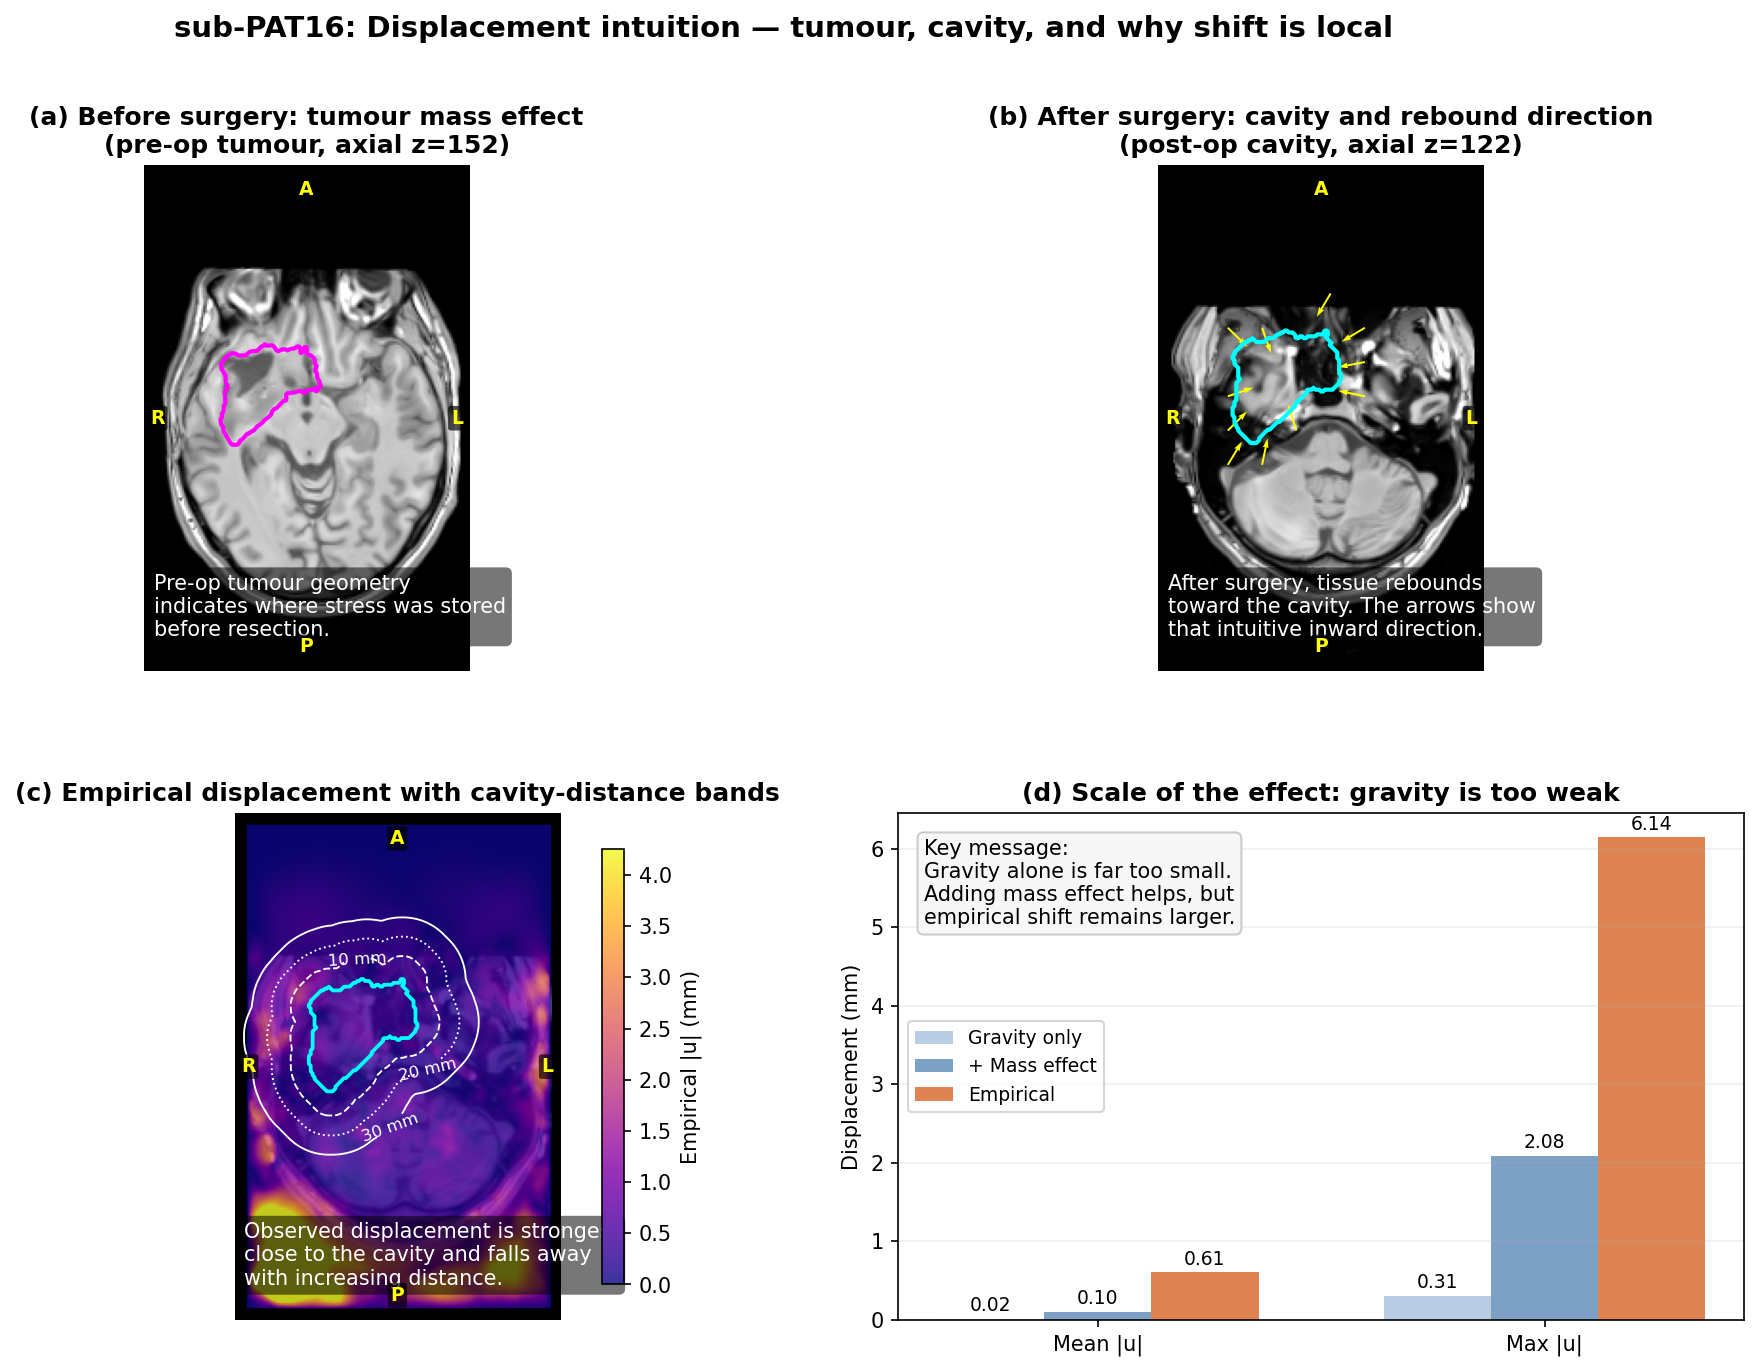

In [57]:
# Section 2 opener: intuitive geometry and displacement insight
#
# This compact figure is intentionally didactic. It links the pre-op tumour,
# the post-op cavity, the observed displacement field, and the overall scale of
# the modelling gap before the more detailed validation figure below.

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy.ndimage import distance_transform_edt
from nibabel.processing import resample_from_to

_ref2 = nib.as_closest_canonical(nib.load(str(LONG_DIR / 'fem_displacement_improved.nii.gz')))

def load_vol_2(path, ref=_ref2, order=1):
    img = nib.as_closest_canonical(nib.load(str(path)))
    if img.shape[:3] != ref.shape[:3] or not np.allclose(img.affine, ref.affine, atol=1e-4):
        img = resample_from_to(img, ref, order=order)
    return np.asarray(img.dataobj).astype(np.float32)

def slc2(vol, z):
    return vol[::-1, :, z].T

def add_orientation_labels(ax):
    kw = dict(transform=ax.transAxes, fontsize=9, fontweight='bold', color='yellow',
              zorder=10, bbox=dict(boxstyle='round,pad=0.15', fc='#000000aa', lw=0))
    ax.text(0.02, 0.50, 'R', va='center', ha='left',   **kw)
    ax.text(0.98, 0.50, 'L', va='center', ha='right',  **kw)
    ax.text(0.50, 0.97, 'A', va='top',    ha='center', **kw)
    ax.text(0.50, 0.03, 'P', va='bottom', ha='center', **kw)

t1_2     = load_vol_2(LONG_DIR / 'T1w_preop_in_postop.nii.gz')
tumor_2  = load_vol_2(LONG_DIR / 'tumor_preop_in_postop.nii.gz', order=0)
cavity_2 = load_vol_2(LONG_DIR / 'cavity_mask_postop.nii.gz', order=0)
emp_2    = load_vol_2(LONG_DIR / 'displacement_magnitude.nii.gz')
impr_2   = load_vol_2(LONG_DIR / 'fem_displacement_improved.nii.gz')
base_2   = load_vol_2(LONG_DIR / 'fem_displacement_magnitude.nii.gz')
brain_2  = impr_2 > 0

z_tum = int(np.argmax((tumor_2 > 0.5).sum(axis=(0, 1))))
z_cav = int(np.argmax((cavity_2 > 0.5).sum(axis=(0, 1))))
vox_mm = float(np.abs(_ref2.affine[0, 0]))
dist_cav = distance_transform_edt(1 - (cavity_2 > 0.5).astype(np.uint8)) * vox_mm

# Rebound-direction arrows on the cavity-centred slice
cav_sl = slc2(cavity_2, z_cav) > 0.5
ys, xs = np.where(cav_sl)
cy, cx = ys.mean(), xs.mean()
Yg, Xg = np.mgrid[0:cav_sl.shape[0]:18, 0:cav_sl.shape[1]:18]
d_sl = slc2(dist_cav, z_cav)
near_band = (d_sl > 4) & (d_sl < 18)
sel = near_band[Yg, Xg]
Xq = Xg[sel]; Yq = Yg[sel]
U = cx - Xq; V = cy - Yq
norm = np.sqrt(U**2 + V**2) + 1e-6
U /= norm; V /= norm

summary = {
    'Gravity only': [float(base_2[brain_2].mean()), float(base_2[brain_2].max())],
    '+ Mass effect': [float(impr_2[brain_2].mean()), float(impr_2[brain_2].max())],
    'Empirical': [float(emp_2[brain_2].mean()), float(emp_2[brain_2].max())],
}

fig = plt.figure(figsize=(16, 10))
gs = GridSpec(2, 2, figure=fig, hspace=0.28, wspace=0.20)
fig.suptitle('sub-PAT16: Displacement intuition — tumour, cavity, and why shift is local',
             fontsize=14, fontweight='bold')

# (a) pre-op tumour geometry
ax = fig.add_subplot(gs[0, 0])
sl = slc2(t1_2, z_tum)
p1, p99 = np.percentile(sl[sl > 0], [1, 99]) if (sl > 0).any() else (0, 1)
ax.imshow(sl, cmap='gray', origin='lower', vmin=p1, vmax=p99)
ax.contour(slc2(tumor_2, z_tum), levels=[0.5], colors=['magenta'], linewidths=[2])
add_orientation_labels(ax)
ax.text(0.03, 0.07,
        'Pre-op tumour geometry\nindicates where stress was stored\nbefore resection.',
        transform=ax.transAxes, fontsize=10, color='white',
        bbox=dict(boxstyle='round', fc='#00000088', lw=0))
ax.set_title(f'(a) Before surgery: tumour mass effect\n(pre-op tumour, axial z={z_tum})', fontweight='bold')
ax.axis('off')

# (b) post-op cavity and rebound direction
ax = fig.add_subplot(gs[0, 1])
sl = slc2(t1_2, z_cav)
p1, p99 = np.percentile(sl[sl > 0], [1, 99]) if (sl > 0).any() else (0, 1)
ax.imshow(sl, cmap='gray', origin='lower', vmin=p1, vmax=p99)
ax.contour(slc2(cavity_2, z_cav), levels=[0.5], colors=['cyan'], linewidths=[2])
ax.quiver(Xq, Yq, U, V, color='yellow', scale=12, width=0.006)
add_orientation_labels(ax)
ax.text(0.03, 0.07,
        'After surgery, tissue rebounds\ntoward the cavity. The arrows show\nthat intuitive inward direction.',
        transform=ax.transAxes, fontsize=10, color='white',
        bbox=dict(boxstyle='round', fc='#00000088', lw=0))
ax.set_title(f'(b) After surgery: cavity and rebound direction\n(post-op cavity, axial z={z_cav})', fontweight='bold')
ax.axis('off')

# (c) empirical displacement with distance bands
ax = fig.add_subplot(gs[1, 0])
sl = slc2(t1_2, z_cav)
p1, p99 = np.percentile(sl[sl > 0], [1, 99]) if (sl > 0).any() else (0, 1)
ax.imshow(sl, cmap='gray', origin='lower', vmin=p1, vmax=p99)
emp_sl = np.ma.masked_where(slc2(emp_2, z_cav) == 0, slc2(emp_2, z_cav))
im = ax.imshow(emp_sl, cmap='plasma', origin='lower', alpha=0.82,
               vmin=0, vmax=np.percentile(emp_2[brain_2], 99))
ax.contour(slc2(cavity_2, z_cav), levels=[0.5], colors=['cyan'], linewidths=[1.8])
cs = ax.contour(slc2(dist_cav, z_cav), levels=[10, 20, 30], colors='white',
                linewidths=[0.9, 0.9, 0.9], linestyles=['--', ':', '-'])
ax.clabel(cs, fmt='%d mm', fontsize=8)
add_orientation_labels(ax)
plt.colorbar(im, ax=ax, shrink=0.86, label='Empirical |u| (mm)')
ax.text(0.03, 0.07,
        'Observed displacement is strongest\nclose to the cavity and falls away\nwith increasing distance.',
        transform=ax.transAxes, fontsize=10, color='white',
        bbox=dict(boxstyle='round', fc='#00000088', lw=0))
ax.set_title('(c) Empirical displacement with cavity-distance bands', fontweight='bold')
ax.axis('off')

# (d) simple scale comparison
ax = fig.add_subplot(gs[1, 1])
metrics = ['Mean |u|', 'Max |u|']
x = np.arange(len(metrics))
w = 0.24
ax.bar(x - w, summary['Gravity only'], width=w, color='#B9CDE5', label='Gravity only')
ax.bar(x,      summary['+ Mass effect'], width=w, color='#7DA1C4', label='+ Mass effect')
ax.bar(x + w,  summary['Empirical'], width=w, color='#DD8452', label='Empirical')
for offs, vals in [(-w, summary['Gravity only']), (0, summary['+ Mass effect']), (w, summary['Empirical'])]:
    for xi, val in zip(x, vals):
        ax.text(xi + offs, val + 0.05, f'{val:.2f}', ha='center', va='bottom', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel('Displacement (mm)')
ax.set_title('(d) Scale of the effect: gravity is too weak', fontweight='bold')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.2)
ax.text(0.03, 0.95,
        'Key message:\nGravity alone is far too small.\nAdding mass effect helps, but\nempirical shift remains larger.',
        transform=ax.transAxes, va='top', fontsize=10,
        bbox=dict(boxstyle='round', fc='#f7f7f7', ec='#cccccc'))

fig.savefig(FIG_DIR / 'figC06_B1_displacement_intuition.png', bbox_inches='tight')
plt.show()

### Interpreting the Displacement Intuition Figure

This figure is meant as a **section opener** for the displacement analysis.  Rather than showing all validation details at once, it gives the reader a compact visual story for why the mechanics problem is centred on the post-op cavity.

**(a) Before surgery: tumour mass effect.**  The pre-op tumour contour marks the region that had been occupying space and mechanically loading adjacent tissue.  This panel reminds the reader that the post-operative shift begins with a pre-operative mass-effect problem.

**(b) After surgery: cavity and rebound direction.**  Once the tumour bulk is removed, the cavity defines the new local geometry.  The inward arrows are a didactic illustration of the intuitive rebound direction toward the cavity, consistent with the body-force interpretation introduced earlier.

**(c) Empirical displacement with cavity-distance bands.**  Overlaying the empirical displacement field with distance contours makes the localisation of the observed shift visually obvious: the strongest displacement clusters close to the cavity wall and weakens farther away.  This is one of the clearest geometric insights in the notebook.

**(d) Scale of the effect.**  The bar chart compresses the quantitative message into one glance: gravity-only FEM is much too weak, adding mass effect clearly improves the result, but the empirical displacement remains larger.  This prepares the reader for the more detailed validation figure below.

Taken together, these panels give a useful mental model for the section: **pre-op tumour mass effect creates stored stress, post-op cavity geometry releases it, and the resulting displacement is strongest in tissue nearest the cavity.**

---
## 3. Interpreting the Results

### What the displacement gap tells us

The gravity-only model produces displacements ~20x smaller than observed,
confirming that **gravity alone cannot explain post-surgical brain shift**.
Adding the mass effect rebound force closes the gap to ~3x, demonstrating
that **tumour interstitial pressure release is the dominant mechanical
driver** of post-operative deformation.

### Remaining gap

The remaining 3x gap likely reflects:
- **Nonlinear mechanics**: Jacobian range [0.55, 1.27] suggests large
  deformations beyond the linear regime
- **CSF redistribution**: not modelled in the current formulation
- **Poroelastic effects**: brain tissue is biphasic (solid + fluid)
- **Time-dependent effects**: creep, viscoelasticity, post-surgical swelling

These are the mathematical challenges discussed in NB\_C09.

---
## 4. Interactive Visualisation with Freeview

> **Desktop only:** Freeview requires a local FreeSurfer installation with a display
> server. These commands will not work in Google Colab. On Colab you can still
> view the static figures generated above.

### Displacement and deformation
```bash
bash scripts/freeview_deformation.sh --subject PAT16
```

This opens displacement magnitude, Jacobian determinant, and cavity mask
overlays on the T1w anatomy.

### Pre-op vs post-op comparison
```bash
bash scripts/freeview_preop_postop.sh --subject PAT16
```

**Tip:** Adjust the opacity slider to blend between pre-op and post-op
views. The brain shift is most visible in the periventricular region
and near the resection cavity.

---
## Summary

In this notebook we have:

- Reviewed the linear elasticity formulation for brain tissue
- Understood the mass effect rebound mechanism
- Loaded and compared three displacement fields (gravity FEM, mass effect FEM, empirical)
- Validated the FEM model against ANTs-derived deformation
- Identified the displacement gap and its implications for model improvement

### Key result

The mass effect mechanism is the dominant physics: adding it closes the
displacement gap from ~20x to ~3x. The remaining gap motivates
hyperelastic, poroelastic, or viscoelastic extensions (NB\_C09).

### Connection to the coupling chain

The FEM displacement field is the input to the mechanics-dynamics coupling
(NB\_C07): displacement $\to$ SC modulation + bifurcation shift $\to$
altered neural dynamics $\to$ predicted FC change.

---

## References

- Budday S et al. (2019). Mechanical characterization of human brain tissue. *Acta Biomaterialia* 48:319--340.
- Miga MI et al. (2001). In vivo quantification of a brain deformation model. *IEEE TMI* 20(12):1384--1397.
- Weickenmeier J et al. (2017). Brain stiffness increases with myelin content. *Acta Biomaterialia* 42:265--272.

---

**Next:** [NB\_C07](NB_C07_Neural_Dynamics.ipynb) -- Neural dynamics and the mechanics-dynamics coupling